#Bibliotecas

In [ ]:
!pip install -q pyecharts

In [ ]:
!pip install pyscipopt

In [ ]:
!pip install pyecharts

# 1 - PDE Didática Código do Professor Marcato


## Aula 2 - Planejamento de Sistemas Elétricos - Aula do Youtube

Esta é aula 2 da disciplina e trata sobre a implementação Python da Técnica de Programação Dinâmica Estocástica "Adptada".

Aula 02a - Planejamento de Sistemas Elétricos (PPEE-UFJF) - PDE "Didática" Python

https://youtu.be/p3FOSrotjzY

Aula 02b - Planejamento de Sistemas Elétricos (PPEE-UFJF) - PDE "Didática" Python

https://youtu.be/1-z_pgRGYis

Aula 02c - Planejamento de Sistemas Elétricos (PPEE-UFJF) - PDE "Didática" Python

https://youtu.be/VSOKiunIc_Y

## Dados do Sistema

In [ ]:
lista_uhe = []

usina = {
    "Nome": "UHE DO MARCATO",
    "Vmax": 100.,
    "Vmin": 20.,
    "Prod": 0.95,
    "Engol": 60.,
    "Afl": [
        [23, 16],
        [19, 14],
        [15, 11]
    ]
}

lista_uhe.append(usina)

usina = {
    "Nome": "GT_1",
    "Capac": 15.,
    "Custo": 10.
}
lista_ute = []
lista_ute.append(usina)

usina = {
    "Nome": "GT_2",
    "Capac": 10.,
    "Custo": 25.
}
lista_ute.append(usina)

d_gerais = {
    "CDef": 500.,
    "Carga": [50., 50., 50.],
    "Nr_Disc": 3,
    "Nr_Est": 3,
    "Nr_Cen": 2
}

sistema = {
    "DGer": d_gerais,
    "UHE": lista_uhe,
    "UTE": lista_ute
}

print(sistema["UTE"][1]["Nome"])

GT_2


## Modelo de Otimização

$$\min\quad C_1\cdot gt_1+C_2\cdot gt_2+CDEF\cdot def+0.01\cdot vvert+\alpha$$

Sujeito ao balanço hídrico, atendimento à demanda, limites operativos e cortes de custo futuro.

$$vf=VI+AFL-vtur-vvert\quad\text{(Balanço Hídrico)}$$

$$\rho\cdot vtur+gt_1+gt_2+def=CARGA\quad\text{(Atendimento à Demanda)}$$

$$\alpha\geq \sum_i a_i\,vf_i+b\quad\text{(Cortes de custo futuro)}$$


## Modelo de Otimização

Criação de uma Função para o Despacho Hidrotérmico

In [ ]:
from cvxopt.modeling import variable, solvers
from cvxopt.modeling import op


def despacho(sistema, VI, AFL, pote_de_corte, iest, imprime):

    Num_UHE = len(sistema["UHE"])
    Num_UTE = len(sistema["UTE"])

    vf = variable(Num_UHE, "Volume Final na Usina")
    vt = variable(Num_UHE, "Volume Turbinado na Usina")
    vv = variable(Num_UHE, "Volume Vertido na Usina")
    gt = variable(Num_UTE, "Geração na Usina Térmica")
    deficit = variable(1, "Déficit de Energia no Sistema")
    alpha = variable(1, "Custo Futuro")

    # Construção da Função Objetivo
    fob = 0

    for i, iusi in enumerate(sistema["UTE"]):
        fob += iusi["Custo"]*gt[i]

    fob += sistema["DGer"]["CDef"]*deficit[0]

    for i, iusi in enumerate(sistema["UHE"]):
        fob += 0.01*vv[i]

    fob += 1.0*alpha[0]

    # Definição das Restrições
    restricoes = []

    # Balanço Hídrico
    for i, iusi in enumerate(sistema["UHE"]):
        restricoes.append(vf[i] == float(VI[i]) + float(AFL[i]) - vt[i] - vv[i])

    # Atendimento à Demanda
    AD = 0

    for i, iusi in enumerate(sistema["UHE"]):
        AD += iusi["Prod"]*vt[i]

    for i, iusi in enumerate(sistema["UTE"]):
        AD += gt[i]

    AD += deficit[0]

    restricoes.append(AD == sistema["DGer"]["Carga"][iest-2])

    # Restrições Canalização
    for i, iusi in enumerate(sistema["UHE"]):
        restricoes.append(vf[i] >= iusi["Vmin"])
        restricoes.append(vf[i] <= iusi["Vmax"])
        restricoes.append(vt[i] >= 0)
        restricoes.append(vt[i] <= iusi["Engol"])
        restricoes.append(vv[i] >= 0)

    for i, iusi in enumerate(sistema["UTE"]):
        restricoes.append(gt[i] >= 0)
        restricoes.append(gt[i] <= iusi["Capac"])

    restricoes.append(deficit[0] >= 0)
    restricoes.append(alpha[0] >= 0)

    for icorte in pote_de_corte:
        if icorte['Estagio'] == iest:
            equacao = 0
            for iusi in range(Num_UHE):
                equacao += float(icorte['Coefs'][iusi])*vf[iusi]
            equacao += float(icorte['Termo_Indep'])
            restricoes.append(alpha[0] >= equacao)

    problema = op(fob, restricoes)
    problema.solve('dense', 'glpk')

    Dger = {
        "Deficit": deficit[0].value()[0],
        "CMO": restricoes[Num_UHE].multiplier.value[0],
        "CustoTotal": fob.value()[0],
        "CustoFuturo": alpha[0].value()[0]
    }

    lista_uhe = []
    for i, iusi in enumerate(sistema["UHE"]):
        resultado = {
            "vf": vf[i].value()[0],
            "vt": vt[i].value()[0],
            "vv": vv[i].value()[0],
            "cma": restricoes[i].multiplier.value[0]
        }
        lista_uhe.append(resultado)

    lista_ute = []
    for i, iusi in enumerate(sistema["UTE"]):
        resultado = {
            "gt": gt[i].value()[0]
        }
        lista_ute.append(resultado)

    resultado = {
        "DGer": Dger,
        "UHE": lista_uhe,
        "UTE": lista_ute
    }

    if imprime:
        print("Custo Total:", fob.value())

        for i, iusi in enumerate(sistema["UHE"]):
            print(vf.name, i, "é", vf[i].value(), "hm3")
            print(vt.name, i, "é", vt[i].value(), "hm3")
            print(vv.name, i, "é", vv[i].value(), "hm3")

        for i, iusi in enumerate(sistema["UTE"]):
            print(gt.name, i, "é", gt[i].value(), "MWmed")

        print(deficit.name, "é", deficit[0].value(), "MWmed")
        print(alpha.name, "é", alpha[0].value(), "$")

        for i, iusi in enumerate(sistema["UHE"]):
            print("O valor da água na usina", i, "é:", restricoes[i].multiplier.value)

        print("O Custo Marginal de Operação é:", restricoes[Num_UHE].multiplier.value)
        print("----- x -----")

    return(resultado)


## Discretizações dos estados e cenários

Varredura regressiva por estágio e volume inicial, com cálculo dos custos médios dos cenários, multiplicadores do balanço hídrico e construção dos cortes da função de custo futuro.

## Gráficos da função de custo futuro

O mesmo bloco calcula e apresenta as curvas por estágio, como na sequência da aula 2C.


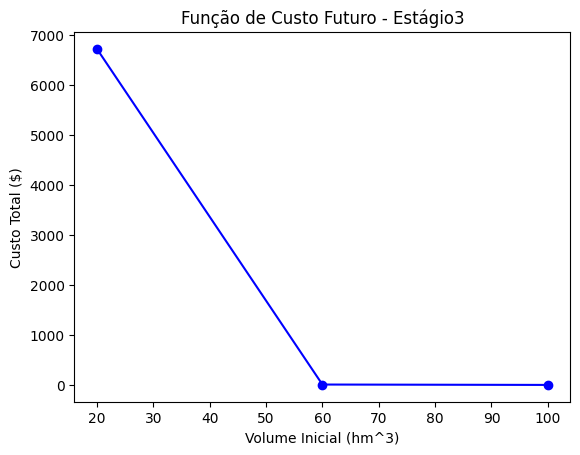

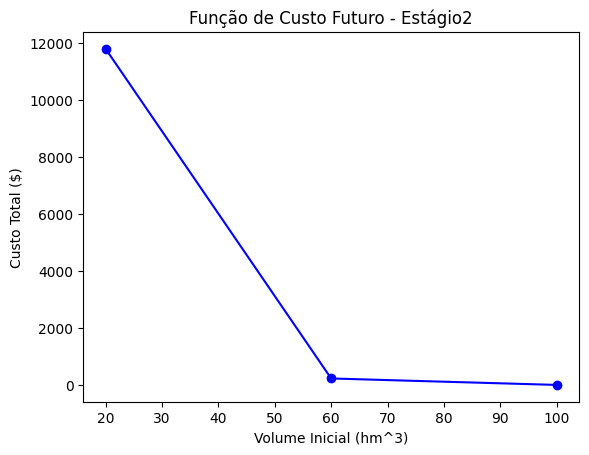

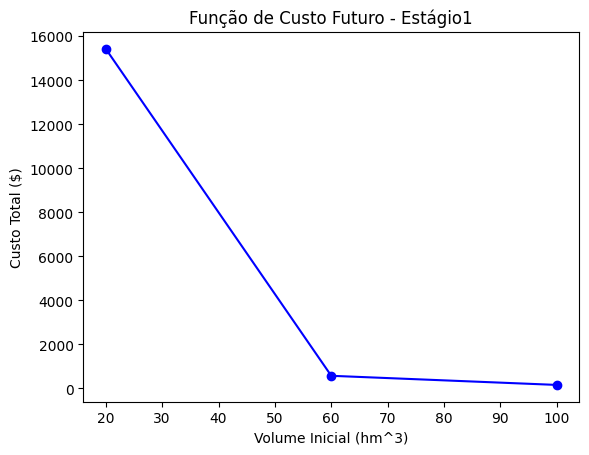

In [ ]:
from itertools import product, tee
import numpy as np
import matplotlib.pyplot as plt

Num_UHE = len(sistema["UHE"])
Num_UTE = len(sistema["UTE"])

passo = 100/(sistema["DGer"]["Nr_Disc"]-1)

discretizacoes = product(np.arange(0,100+passo,passo), repeat = Num_UHE)
discretizacoes = list(discretizacoes)

pote_de_corte = []

for iest in np.arange(sistema["DGer"]["Nr_Est"],0,-1):
    if Num_UHE == 1:
        plt.figure(iest)
        plt.title("Função de Custo Futuro - Estágio"+str(iest))
        plt.xlabel("Volume Inicial (hm^3)")
        plt.ylabel("Custo Total ($)")
        eixox = []
        eixoy = []
    for discretizacao in discretizacoes:
        VI = []
        for i, iusi in enumerate(sistema["UHE"]):
            VI.append(iusi["Vmin"] + (iusi["Vmax"]-iusi["Vmin"])*discretizacao[i]/100)
        if Num_UHE == 1:
            eixox.append(VI[0])
        media = 0.
        media_cma = []
        for i, iusi in enumerate(sistema["UHE"]):
            media_cma.append(0)
        for icen in np.arange(0,sistema["DGer"]["Nr_Cen"]):
            AFL = []
            for i, iusi in enumerate(sistema["UHE"]):
                AFL.append(iusi["Afl"][iest-1][icen])
            #print(iest, discretizacao, VI, icen,AFL)
            resultado = despacho(sistema,VI,AFL, pote_de_corte, iest+1, imprime = False)
            media += resultado["DGer"]["CustoTotal"]
            for i, iusi in enumerate(resultado["UHE"]):
                media_cma[i] += iusi["cma"]
        media = media/sistema["DGer"]["Nr_Cen"]
        term_indep = media
        for i, iusi in enumerate(resultado["UHE"]):
            media_cma[i] = -media_cma[i] / sistema["DGer"]["Nr_Cen"]
            term_indep -= VI[i]*media_cma[i]
        corte = {
            "Estagio": iest,
            "Termo_Indep": term_indep,
            "Coefs": media_cma
        }
        pote_de_corte.append(corte)

        if Num_UHE == 1:
            eixoy.append(media)
    if Num_UHE == 1:
        plt.plot(eixox,eixoy,marker="o",color="blue")

#despacho(sistema, [62], [8], pote_de_corte, 2, imprime=True)


PDE Didática# Nova seção

PDE Didática

#2 - PDE Didática 1 UHE Código Adptado Trabalho 1


## 1. Introdução e Objetivo

O planejamento energético é importante para definir a melhor forma de utilizar as usinas disponíveis, buscando atender à demanda de energia com o menor custo possível.

Neste trabalho, vamos analisar o despacho hidrotérmico da UHE Batalha, junto com duas usinas de biomassa, ERB Candeias e BBF Baliza. A ideia é avaliar quanto cada usina deve gerar e como utilizar a água armazenada no reservatório da hidrelétrica ao longo do ano.

Um dos principais pontos é decidir se vale mais a pena utilizar a água para gerar energia no momento ou acionar as termelétricas para guardar essa água para os próximos meses. Isso é importante porque utilizar muita água no início pode causar problemas nos meses seguintes, principalmente em períodos de pouca chuva.

Para isso, vamos utilizar um código em Python desenvolvido em sala de aula, baseado em programação dinâmica regressiva. O programa realiza os cálculos de trás para frente, começando em dezembro e terminando em janeiro, considerando os custos futuros para ajudar nas decisões de geração.

A análise será feita para 12 meses, considerando dois cenários de afluência, um otimista e outro pessimista. Ao final, vamos comparar a geração das usinas, os volumes de água armazenados e os custos de operação em cada cenário, buscando entender como o planejamento influencia as decisões ao longo do ano.

## 2. Formulação Matemática

Para realizar o planejamento energético, utilizamos um modelo de otimização que busca atender à demanda de energia com o menor custo possível, considerando a geração da hidrelétrica, das duas termelétricas e a quantidade de água armazenada no reservatório.

O programa utiliza algumas equações para definir quanto cada usina deve gerar e qual será o volume de água disponível no final de cada mês.

### 2.1. Balanço hídrico

O balanço hídrico calcula a quantidade de água que ficará armazenada no reservatório após considerar a água que entrou, a que foi utilizada para gerar energia e a que foi vertida.

$$
V_f = V_i + (Q_{afl} - Q_t - Q_v)\cdot k
$$

Onde:

- **Vf:** volume final do reservatório (hm³).
- **Vi:** volume inicial do reservatório (hm³).
- **Qafl:** vazão afluente (m³/s).
- **Qt:** vazão utilizada para geração (m³/s).
- **Qv:** vazão vertida (m³/s).
- **k:** fator de conversão de vazão para volume, sendo 2,592 para um período de 30 dias.

O volume final precisa respeitar os limites mínimo e máximo da UHE Batalha.

### 2.2. Atendimento à demanda

A soma da energia gerada pelas três usinas deve atender à carga estabelecida de 50 MW. Caso a geração não seja suficiente, o programa considera um déficit de energia.

$$
\rho \cdot Q_t + GT_1 + GT_2 + DEF = 50
$$

Onde:

- **ρ:** produtividade da UHE Batalha, fixada em 0,3551 MW/(m³/s).
- **Qt:** vazão turbinada pela hidrelétrica.
- **GT1:** geração da ERB Candeias (MW).
- **GT2:** geração da BBF Baliza (MW).
- **DEF:** potência não atendida (MW).

### 2.3. Função objetivo

A função objetivo busca encontrar a operação com o menor custo, considerando o gasto com as termelétricas, possíveis déficits, o vertimento e o custo futuro de utilizar a água armazenada.

$$
\min \left[ 720(CT_1GT_1 + CT_2GT_2 + CDEF \cdot DEF) + 0{,}01 \cdot Q_v \cdot k + \alpha \right]
$$

Onde:

- **CT1 e CT2:** custos de geração das termelétricas (R$/MWh).

- **GT1 e GT2:** potência gerada pelas termelétricas (MW).
- **CDEF:** custo do déficit de energia (R$/MWh).
- **DEF:** potência não atendida (MW).
- **720:** quantidade de horas consideradas em cada mês.
- **Qv:** vazão vertida (m³/s).
- **k:** fator de conversão de vazão para volume (2,592).
- **α (alfa):** custo futuro estimado pelo programa.
- **0,01:** pequena penalidade atribuída ao vertimento no modelo.

O custo futuro é importante porque permite que o programa avalie se vale mais a pena utilizar a água no mês atual ou guardá-la para os meses seguintes.

### 2.4. Restrições do modelo

O programa também precisa respeitar os limites de operação das usinas. Para a UHE Batalha, o volume do reservatório deve permanecer entre 430,05 hm³ e 1.781,61 hm³, e a vazão turbinada não pode ultrapassar 147 m³/s.

As termelétricas também possuem limites de geração, sendo 17 MW para a ERB Candeias e 18 MW para a BBF Baliza.

Essas restrições garantem que o programa procure a solução mais econômica dentro dos limites definidos para o sistema.

In [ ]:
from pyscipopt import Model


def despacho_hidrotermico(
    VI, AFL, CARGA, ro,
    GTMAX1, GTMAX2, CT1, CT2, CDEF,
    ENGOL, VMIN, VMAX, RETAS
):
    modelo = Model("despacho_hidrotermico")

    # Duração padrão de cada estágio: 30 dias
    horas = 720

    # Conversão de vazão (m³/s) para volume (hm³)
    k = 2.592

    #modelo.hideOutput()
    # Variáveis de decisão
    vf = modelo.addVar("vf", lb=VMIN, ub=VMAX)
    vt = modelo.addVar("vt", lb=0, ub=ENGOL)
    vv = modelo.addVar("vv", lb=0)
    gt1 = modelo.addVar("gt1", lb=0, ub=GTMAX1)
    gt2 = modelo.addVar("gt2", lb=0, ub=GTMAX2)
    deficit = modelo.addVar("def", lb=0)
    alpha = modelo.addVar("alpha", lb=0 )

    # Balanço hídrico e atendimento à carga
    modelo.addCons(vf == VI + (AFL - vt - vv) * k)
    modelo.addCons(ro * vt + gt1 + gt2 + deficit == CARGA)

    for reta in RETAS:
      modelo.addCons(alpha >= reta['coef_ang']*vf + reta['term_ind'])

    # Função objetivo (CALCULO DA FOB)
    modelo.setObjective(
        horas * (CT1 * gt1 + CT2 * gt2 + CDEF * deficit)
        + 0.01 * vv * k + alpha,
        sense="minimize"
    )

    modelo.optimize()

    if modelo.getStatus() != "optimal":
        raise RuntimeError(
            f"Não foi encontrada solução ótima. Status: {modelo.getStatus()}"
        )

    return {
        "fob": modelo.getObjVal(),
        "vf": modelo.getVal(vf),
        "vt": modelo.getVal(vt),
        "vv": modelo.getVal(vv),
        "gt1": modelo.getVal(gt1),
        "gt2": modelo.getVal(gt2),
        "def": modelo.getVal(deficit),
        "alpha": modelo.getVal(alpha)
    }

In [ ]:
from pyecharts import options as opts
from pyecharts.charts import Line
from IPython.display import HTML, display


def plotar_custo_futuro(VI, FOB, estagio):
    if len(VI) != len(FOB):
        raise ValueError("VI e FOB devem ter o mesmo número de elementos.")
    if len(VI) == 0:
        raise ValueError("VI e FOB não podem estar vazios.")

    # Ordena pelo volume inicial, preservando os pares.
    pontos = sorted(zip(VI, FOB))
    volumes, custos = map(list, zip(*pontos))

    grafico = (
        Line(init_opts=opts.InitOpts(width="900px", height="500px"))
        .add_xaxis(volumes)
        .add_yaxis(
            series_name="Custo futuro",
            y_axis=custos,
            is_smooth=False,
            is_symbol_show=True,
            symbol="circle",
            symbol_size=9,
            label_opts=opts.LabelOpts(is_show=False),
            linestyle_opts=opts.LineStyleOpts(width=2),
        )
        .set_global_opts(
            title_opts=opts.TitleOpts(
                title="Função de custo futuro estágio "+str(estagio),
                pos_left="center",
                pos_top="top",
            ),
            legend_opts=opts.LegendOpts(is_show=False),
            xaxis_opts=opts.AxisOpts(
                type_="value",
                name="VI — Volume inicial (hm³) do estagio"+str(estagio),
                name_location="middle",
                name_gap=30,
            ),
            yaxis_opts=opts.AxisOpts(
                type_="value",
                name="FOB (R$)",
                name_location="middle",
                name_gap=60,
                splitline_opts=opts.SplitLineOpts(is_show=True),
            ),
            tooltip_opts=opts.TooltipOpts(trigger="axis"),
        )
    )

    display(HTML(grafico.render_embed()))
    return grafico


## 3. Caracterização das Usinas

Para realizar o planejamento energético, foram selecionadas três usinas: uma hidrelétrica e duas termelétricas de biomassa. Os dados utilizados foram obtidos na plataforma PySDDP-MDDH, a partir das informações das usinas presentes no caso de estudo.

### 3.1. UHE Batalha (020)

A UHE Batalha será responsável pela geração hidrelétrica do sistema. Sua geração depende da quantidade de água disponível no reservatório e da vazão utilizada nas turbinas.

Os principais dados da usina são:

| Parâmetro | Valor |
|---|---|
| Potência nominal | 52,50 MW |
| Tipo de turbina | Kaplan |
| Vazão nominal | 154 m³/s = 399,17 hm³/mês|
| Engolimento máximo considerado | 147 m³/s = 381,02 hm³/mês|
| Volume máximo | 1.781,61 hm³ |
| Volume mínimo | 430,05 hm³ |
| Volume útil | 1.351,56 hm³ |
| Produtividade adotada | 0,3551 MW/(m³/s) = 0,1370 MW/(hm³/mês)|

Para simplificar os cálculos, a produtividade foi mantida constante em 0,3551 MW/(m³/s) durante todos os meses, mesmo que na prática ela possa variar conforme o nível do reservatório.

Também foi considerado que o reservatório começa janeiro com 430,05 hm³, que corresponde ao volume mínimo operacional.

### 3.2. UTE ERB Candeias (106)

A ERB Candeias é uma usina termelétrica de biomassa que será utilizada para complementar a geração hidrelétrica quando necessário.

| Parâmetro | Valor |
|---|---|
| Combustível | Biomassa |
| Potência máxima | 17 MW |
| Custo variável unitário (CVU) | R$ 118,93/MWh |

Por apresentar o menor custo variável entre as duas termelétricas, a ERB Candeias tende a ser utilizada primeiro quando é necessário complementar a geração da UHE Batalha.

### 3.3. UTE BBF Baliza (322)

A BBF Baliza também é uma usina termelétrica de biomassa, mas apresenta um custo de geração maior que a ERB Candeias.

| Parâmetro | Valor |
|---|---|
| Combustível | Biomassa |
| Potência máxima | 18 MW |
| Custo variável unitário (CVU) | R$ 917,12/MWh |

Devido ao seu custo mais elevado, a BBF Baliza tende a ser acionada quando a geração da hidrelétrica e da ERB Candeias não é suficiente ou quando o modelo identifica vantagem econômica em preservar água para os meses seguintes.

### 3.4. Condições adotadas para o planejamento

Além dos dados das usinas, foram definidos alguns parâmetros para a simulação.

| Parâmetro | Valor |
|---|---|
| Demanda de energia | 50 MW |
| Horizonte de planejamento | 12 meses |
| Duração considerada por mês | 30 dias (720 horas) |
| Cenários de afluência | Otimista e pessimista |
| Probabilidade de cada cenário | 50% |
| Custo do déficit | R$ 8.291,00/MWh |
| Discretizações do reservatório | 100 |

O modelo busca atender à demanda de 50 MW utilizando as três usinas, sempre respeitando seus limites de geração e armazenamento.

Nos meses de pouca afluência, pode ser necessário utilizar mais geração térmica ou até ocorrer déficit. Já nos meses de maior afluência, o programa pode utilizar a geração hidrelétrica e armazenar parte da água para os meses seguintes.

Com essas informações, serão realizadas as simulações para os 12 meses, buscando encontrar a operação de menor custo considerando os cenários hidrológicos.

## 4. Programação Dinâmica Regressiva

Para realizar o planejamento dos 12 meses, utilizamos a programação dinâmica regressiva, que consiste em fazer os cálculos de trás para frente, começando em dezembro e terminando em janeiro.

Essa metodologia é importante porque não podemos decidir quanto de água utilizar em um mês considerando apenas o custo daquele momento. Se utilizarmos muita água no início do ano, podemos ficar com pouca água nos meses seguintes, principalmente durante os períodos de menor afluência.

### 4.1. Como funciona o cálculo

Primeiro, o programa calcula dezembro, que é o último estágio do planejamento. Nesse mês, ele avalia o custo de geração para diferentes volumes iniciais do reservatório, considerando os cenários otimista e pessimista.

Depois, o programa calcula novembro, mas agora já possui as informações dos custos de dezembro. Assim, consegue avaliar se vale a pena utilizar mais água em novembro ou guardar parte dela para dezembro.

Esse processo continua até chegar em janeiro. Dessa forma, quando o programa calcula o primeiro mês, já possui uma estimativa dos custos de operação dos meses seguintes.

### 4.2. Discretização do reservatório

Para realizar esses cálculos, o programa divide o intervalo entre o volume mínimo e o volume máximo da UHE Batalha em 100 pontos.

Os volumes analisados vão de 430,05 hm³ até 1.781,61 hm³.

Para cada um desses volumes, o programa calcula o custo de operação considerando as duas possibilidades de afluência do mês.

Com os resultados, são construídas as funções de custo futuro, que mostram como o custo de operação varia conforme a quantidade de água disponível no reservatório.

### 4.3. Função de custo futuro

A função de custo futuro permite que o programa estime quanto custará operar o sistema nos meses seguintes, dependendo da quantidade de água que ficar armazenada no final do mês atual.

Por exemplo, em janeiro, o programa pode escolher entre utilizar mais água para gerar energia ou acionar uma termelétrica para preservar parte dessa água.

Se o custo de utilizar a termelétrica em janeiro for menor que a economia esperada nos meses seguintes, pode valer a pena guardar água.

Por outro lado, se essa economia futura não compensar o gasto com a termelétrica, o programa pode decidir aumentar a geração hidrelétrica.

No código, os custos futuros são representados por retas, utilizadas na otimização por meio da variável alfa (α).

### 4.4. Simulação da operação ao longo do ano

Depois de calcular as funções de custo futuro de dezembro até janeiro, realizamos a simulação da operação na ordem normal dos meses.

Começamos janeiro com o volume inicial de 430,05 hm³. O programa calcula quanto cada usina deve gerar e qual será o volume final do reservatório.

Esse volume final passa a ser o volume inicial de fevereiro, e o processo continua até dezembro.

Foram realizadas duas simulações: uma considerando as afluências pessimistas durante todo o ano e outra considerando as otimistas.

Com isso, conseguimos comparar a geração das usinas, os volumes armazenados, a ocorrência de déficit e os custos de operação nos dois cenários.

## 5. Função de Custo Futuro e Análise dos Gráficos

Após realizar a programação dinâmica regressiva, o programa gera os gráficos das funções de custo futuro para os 12 meses do planejamento.

Esses gráficos mostram a relação entre o volume inicial de água no reservatório da UHE Batalha e o custo de operação calculado pelo modelo.

No eixo horizontal (X), temos o volume inicial do reservatório em hm³. Já no eixo vertical (Y), temos o valor da função objetivo (FOB), em reais, considerando o custo do estágio analisado e os custos futuros estimados.

### 5.1. Comportamento das curvas

De maneira geral, podemos observar que os custos diminuem conforme aumenta o volume inicial do reservatório.

Isso acontece porque, com mais água disponível, a UHE Batalha consegue gerar mais energia, reduzindo a necessidade de utilizar as termelétricas, que possuem custos de geração mais elevados.

Quando o reservatório está próximo do volume mínimo de 430,05 hm³, os custos tendem a ser maiores, principalmente nos meses com pouca afluência.

Já com volumes mais elevados, o sistema possui maior disponibilidade de água, permitindo reduzir a geração termelétrica e o risco de déficit.

### 5.2. Diferença entre os estágios

Os gráficos apresentam valores diferentes porque cada mês possui suas próprias afluências e considera um período diferente de custos futuros.

Em dezembro, por ser o último estágio, o programa considera apenas o custo de operação daquele mês, sem acrescentar custos dos meses seguintes.

Em novembro, o programa considera o custo imediato de novembro e o custo futuro estimado de dezembro.

Esse processo continua até janeiro, que considera o custo de janeiro e uma estimativa dos custos de fevereiro até dezembro.

Por isso, os valores dos gráficos não representam apenas os gastos do mês indicado, mas também os custos futuros considerados pelo modelo.

### 5.3. Importância da água armazenada

As curvas ajudam a entender que a água armazenada possui um valor para o planejamento energético.

Nem sempre utilizar toda a água disponível para gerar energia no mês atual será a melhor decisão. Em alguns casos, pode compensar utilizar uma termelétrica mais barata e preservar água para períodos futuros.

Por outro lado, quando o reservatório possui bastante água ou existe previsão de grandes afluências, o programa pode optar por aumentar a geração hidrelétrica.

Essa escolha é feita buscando o menor custo total de operação, respeitando os limites das usinas e do reservatório.

### 5.4. Apresentação dos resultados

Para facilitar a visualização, foram utilizadas 100 discretizações do volume do reservatório em cada estágio, mas apenas 10 valores foram selecionados para apresentação nas tabelas.

Essa escolha permite manter o detalhamento dos cálculos e apresentar os resultados de forma mais organizada.

Os gráficos e as tabelas serão utilizados para analisar como o custo futuro varia conforme o volume inicial e para entender as decisões de geração ao longo dos 12 meses.

In [ ]:

import numpy as np
import pandas as pd

from pyecharts import options as opts
from pyecharts.charts import Line
from IPython.display import HTML, display


# ============================================================
# 1. PARÂMETROS DA PDE DIDÁTICA
# ============================================================

discret = 10

# Volumes da UHE Batalha
VMIN = 430.05
VMAX = 1781.61

VI = [
    VMIN + i * ((VMAX - VMIN) / (discret - 1))
    for i in range(discret)
]

# Afluências: cenário pessimista e otimista
# PARA AS AFLUENCIAS FORAM PEGADOS OS VALORES MAXIMO E MINIMO HISTORICOS
AFL = [
    [47, 352],   # Janeiro
    [42, 471],   # Fevereiro
    [55, 502]    # Março
    # [38, 203],  # Abril
    # [26, 170],  # Maio
    # [24, 125],  # Junho
    # [17, 95],   # Julho
    # [14, 76],   # Agosto
    # [11, 74],   # Setembro
    # [8, 115],   # Outubro
    # [13, 266],  # Novembro
    # [19, 385]   # Dezembro
]


# ============================================================
# 2. FUNÇÃO GRÁFICA — SOMENTE APROXIMAÇÃO AZUL
# ============================================================

def plotar_fcf_azul(VI, FOB, estagio):

    # Eixo Y ajustado ao custo máximo de cada estágio
    limite_y = float(
        np.ceil(max(FOB) * 1.15 / 1000000)
        * 1000000
    )

    limite_y = max(limite_y, 1000000)

    # Criar gráfico
    grafico = Line(
        init_opts=opts.InitOpts(
            width="1100px",
            height="650px"
        )
    )

    # Volumes no eixo X
    grafico.add_xaxis([
        float(v) for v in VI
    ])

    # Linha azul: pontos da FOB conectados
    grafico.add_yaxis(
        series_name="Aproximação linear por partes (superior)",
        y_axis=[float(custo) for custo in FOB],
        is_smooth=False,
        is_symbol_show=True,
        symbol="circle",
        symbol_size=9,

        label_opts=opts.LabelOpts(
            is_show=False
        ),

        linestyle_opts=opts.LineStyleOpts(
            color="#5470C6",
            width=3
        ),

        itemstyle_opts=opts.ItemStyleOpts(
            color="#5470C6"
        )
    )

    # ========================================================
    # TÍTULO, LEGENDA E EIXOS
    # ========================================================

    grafico.set_global_opts(

        title_opts=opts.TitleOpts(
            title=f"Função de custo futuro — Estágio {estagio}",
            pos_left="center",
            pos_top="2%",

            title_textstyle_opts=opts.TextStyleOpts(
                font_size=22,
                font_weight="bold"
            )
        ),

        legend_opts=opts.LegendOpts(
            is_show=True,
            pos_top="11%",
            pos_left="center",
            orient="horizontal",
            selected_mode=False,

            textstyle_opts=opts.TextStyleOpts(
                font_size=15
            )
        ),

        xaxis_opts=opts.AxisOpts(
            type_="value",
            name="VI — Volume inicial (hm³)",
            name_location="middle",
            name_gap=40,
            min_=400,
            max_=1800,

            name_textstyle_opts=opts.TextStyleOpts(
                font_size=17
            ),

            axislabel_opts=opts.LabelOpts(
                font_size=15
            )
        ),

        yaxis_opts=opts.AxisOpts(
            type_="value",
            name="FOB (R$)",
            name_location="middle",
            name_gap=75,
            min_=0,
            max_=limite_y,

            name_textstyle_opts=opts.TextStyleOpts(
                font_size=17
            ),

            axislabel_opts=opts.LabelOpts(
                font_size=15
            ),

            splitline_opts=opts.SplitLineOpts(
                is_show=True
            )
        ),

        tooltip_opts=opts.TooltipOpts(
            trigger="axis"
        )
    )

    # ========================================================
    # LEGENDA — SOMENTE A LINHA AZUL
    # ========================================================

    grafico.options["legend"][0]["data"] = [
        "Aproximação linear por partes (superior)"
    ]

    grafico.options["legend"][0]["icon"] = "roundRect"
    grafico.options["legend"][0]["itemWidth"] = 26
    grafico.options["legend"][0]["itemHeight"] = 5

    # Mesmo espaçamento visual do bloco de testes
    grafico.options["grid"] = {
        "top": "25%",
        "bottom": "18%",
        "left": "14%",
        "right": "6%"
    }

    display(HTML(grafico.render_embed()))

    return grafico


# ============================================================
# 3. PROGRAMAÇÃO DINÂMICA ESTOCÁSTICA
# ============================================================

RETAS_ANT = list()

# Armazenar resultados dos estágios
RETAS_POR_ESTAGIO = {}
FOB_POR_ESTAGIO = {}

# Resolver de trás para frente: março, fevereiro, janeiro
for estagio in np.arange(3, 0, -1):

    FOB = list()
    RETAS = list()

    for VOL in VI:

        media = 0

        # Dois cenários de afluência
        for cenario in AFL[estagio - 1]:

            resultado = despacho_hidrotermico(
                VOL,
                cenario,
                CARGA=50,
                ro=0.3378,
                GTMAX1=17,
                GTMAX2=18,
                CT1=118.93,
                CT2=917.12,
                CDEF=8291,
                ENGOL=147,
                VMIN=VMIN,
                VMAX=VMAX,
                RETAS=RETAS_ANT
            )

            media += resultado["fob"]

        # Média dos cenários
        media = media / len(AFL[estagio - 1])

        FOB.append(media)

        posicao = len(FOB)

        # Construir retas entre pontos consecutivos
        if VOL != VMIN:

            A = np.array([
                [VI[posicao - 2], 1],
                [VI[posicao - 1], 1]
            ])

            B = np.array([
                FOB[-2],
                FOB[-1]
            ])

            [a, b] = np.linalg.solve(A, B)

            RETAS.append({
                "coef_ang": a,
                "term_ind": b
            })

    # ========================================================
    # GRÁFICO DO ESTÁGIO
    # ========================================================

    grafico = plotar_fcf_azul(
        VI,
        FOB,
        estagio
    )

    # Atualizar retas para o estágio anterior
    RETAS_ANT = RETAS.copy()

    # Armazenar retas
    RETAS_POR_ESTAGIO[int(estagio)] = RETAS.copy()

    # Armazenar custos
    FOB_POR_ESTAGIO[int(estagio)] = FOB.copy()

    # ========================================================
    # TABELA DE RESULTADOS
    # ========================================================

    print(f"\n===== ESTÁGIO {estagio} =====")

    print(
        "Volume inicial (hm³) | "
        "FOB calculada (R$) | "
        "Alpha pelas retas (R$)"
    )

    print("-" * 72)

    indices = range(len(VI))

    for i in indices:

        volume = VI[i]

        valores_retas = [
            reta["coef_ang"] * volume
            + reta["term_ind"]
            for reta in RETAS
        ]

        alpha_estimado = (
            max(0, max(valores_retas))
            if RETAS
            else 0
        )

        print(
            f"{volume:19.2f} | "
            f"{FOB[i]:18.2f} | "
            f"{alpha_estimado:23.2f}"
        )


# ============================================================
# 4. VALIDAÇÃO DAS RETAS (SEM EXIBIÇÃO EXTRA)
# ============================================================

# Mantida para consulta, sem gerar outra tabela visual.
retas = RETAS_POR_ESTAGIO[int(estagio)]

volumes_teste = np.linspace(
    VMIN,
    VMAX,
    discret
)

resultados_teste = []

for volume in volumes_teste:

    valores = [
        reta["coef_ang"] * volume
        + reta["term_ind"]
        for reta in retas
    ]

    alpha_estimado = max(
        0,
        max(valores)
    )

    resultados_teste.append({
        "Volume (hm³)": volume,
        "Alpha pelas retas (R$)": alpha_estimado
    })

tabela_validacao = pd.DataFrame(
    resultados_teste
)



===== ESTÁGIO 3 =====
Volume inicial (hm³) | FOB calculada (R$) | Alpha pelas retas (R$)
------------------------------------------------------------------------
             430.05 |         5503837.71 |              5503837.71
             580.22 |          522049.39 |               522049.39
             730.40 |           29405.20 |                29405.20
             880.57 |           29405.30 |                29405.30
            1030.74 |           29406.05 |                29406.05
            1180.92 |           29406.80 |                29406.80
            1331.09 |           29407.55 |                29407.55
            1481.26 |           29408.30 |                29408.30
            1631.44 |           29409.05 |                29409.05
            1781.61 |           29409.81 |                29409.81



===== ESTÁGIO 2 =====
Volume inicial (hm³) | FOB calculada (R$) | Alpha pelas retas (R$)
------------------------------------------------------------------------
             430.05 |        11876933.30 |             11876933.30
             580.22 |         3412601.89 |              3412601.89
             730.40 |          985795.38 |               985795.38
             880.57 |          258901.42 |               258901.42
            1030.74 |           58813.16 |                58813.16
            1180.92 |           58814.02 |                58814.02
            1331.09 |           58815.15 |                58815.15
            1481.26 |           58816.28 |                58816.28
            1631.44 |           58817.40 |                58817.40
            1781.61 |           58818.53 |                58818.53



===== ESTÁGIO 1 =====
Volume inicial (hm³) | FOB calculada (R$) | Alpha pelas retas (R$)
------------------------------------------------------------------------
             430.05 |        12410133.22 |             12410133.22
             580.22 |         6181104.09 |              6181104.09
             730.40 |         2326500.22 |              2326500.22
             880.57 |         1160057.67 |              1160057.67
            1030.74 |          452128.86 |               452128.86
            1180.92 |          160853.38 |               160853.38
            1331.09 |           88221.57 |                88221.57
            1481.26 |           88222.79 |                88222.79
            1631.44 |           88224.10 |                88224.10
            1781.61 |           88225.42 |                88225.42


## 6. Aproximação Inferior da Função de Custo Futuro (FCF) por Retas de Suporte

Este bloco constrói uma aproximação inferior da Função de Custo Futuro (FCF) utilizando retas tangentes obtidas a partir dos multiplicadores duais.

As retas tangentes são utilizadas para formar a aproximação inferior da FCF nos três estágios da PDE.

In [ ]:

# ============================================================
# TESTE INDEPENDENTE — PDE COM 3 ESTÁGIOS
# APROXIMAÇÃO LINEAR POR PARTES E CORTES DE SUPORTE
# GRÁFICOS: PYECHARTS
# ============================================================

import numpy as np
from pyscipopt import Model, SCIP_PARAMSETTING
from pyecharts import options as opts
from pyecharts.charts import Line
from IPython.display import HTML, display


# ============================================================
# 1. PARÂMETROS
# ============================================================

VMIN_TESTE = 430.05
VMAX_TESTE = 1781.61
DISCRET_TESTE = 10

K = 2.592
HORAS_TESTE = 720

# Dois cenários equiprováveis por estágio
AFL_ESTAGIOS = {
    1: [47, 352],   # Janeiro
    2: [42, 471],   # Fevereiro
    3: [55, 502]    # Março
}

NOMES_ESTAGIOS = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março"
}


# ============================================================
# 2. DESPACHO HIDROTÉRMICO COM MULTIPLICADOR DUAL
# ============================================================

def resolver_despacho_com_dual(
    vi, afl, retas_futuras
):

    modelo = Model("despacho_dual")
    modelo.hideOutput()

    modelo.setPresolve(SCIP_PARAMSETTING.OFF)
    modelo.setHeuristics(SCIP_PARAMSETTING.OFF)
    modelo.disablePropagation()

    # Variáveis hidráulicas
    vf = modelo.addVar(
        "vf", lb=VMIN_TESTE, ub=VMAX_TESTE
    )

    vt = modelo.addVar("vt", lb=0, ub=147)
    vv = modelo.addVar("vv", lb=0)

    # Térmicas e déficit
    gt1 = modelo.addVar("gt1", lb=0, ub=17)
    gt2 = modelo.addVar("gt2", lb=0, ub=18)
    deficit = modelo.addVar("def", lb=0)

    # Custo futuro
    alpha = modelo.addVar("alpha", lb=0)

    # Balanço hídrico
    balanco = modelo.addCons(
        vf + K * vt + K * vv == vi + K * afl
    )

    # Atendimento à demanda
    modelo.addCons(
        0.3551 * vt + gt1 + gt2 + deficit == 50
    )

    # Retas de suporte do estágio seguinte
    for a, b in retas_futuras:
        modelo.addCons(
            alpha >= a * vf + b
        )

    # Último estágio: sem custo futuro
    if not retas_futuras:
        modelo.addCons(alpha == 0)

    # Custo imediato + custo futuro
    custo_imediato = (
        HORAS_TESTE * (
            118.93 * gt1
            + 917.12 * gt2
            + 8291 * deficit
        )
        + 0.01 * vv * K
    )

    modelo.setObjective(
        custo_imediato + alpha,
        sense="minimize"
    )

    modelo.optimize()

    if modelo.getStatus() != "optimal":
        raise RuntimeError(
            f"Problema não ótimo: {modelo.getStatus()}"
        )

    custo = modelo.getObjVal()

    # Inclinação marginal da função de custo
    inclinacao = modelo.getDualsolLinear(
        balanco
    )

    return custo, inclinacao


# ============================================================
# 3. CUSTO ESPERADO DE CADA ESTÁGIO
# ============================================================

def custo_esperado_estagio(
    volume, estagio, retas_futuras
):

    custos_cenarios = []
    inclinacoes_cenarios = []

    for afluencia in AFL_ESTAGIOS[estagio]:

        custo, inclinacao = resolver_despacho_com_dual(
            float(volume),
            afluencia,
            retas_futuras
        )

        custos_cenarios.append(custo)
        inclinacoes_cenarios.append(inclinacao)

    # Média dos dois cenários
    custo_medio = np.mean(custos_cenarios)
    inclinacao_media = np.mean(
        inclinacoes_cenarios
    )

    return custo_medio, inclinacao_media


# ============================================================
# 4. PROGRAMAÇÃO DINÂMICA — DE TRÁS PARA FRENTE
# ============================================================

volumes = np.linspace(
    VMIN_TESTE,
    VMAX_TESTE,
    DISCRET_TESTE
)

CUSTOS_POR_ESTAGIO = {}
INCLINACOES_POR_ESTAGIO = {}
RETAS_SUPORTE_POR_ESTAGIO = {}

# Estágio 4 não existe: custo terminal = zero
RETAS_SUPORTE_POR_ESTAGIO[4] = []

for estagio in [3, 2, 1]:

    custos = []
    inclinacoes = []

    # Cortes calculados para o estágio seguinte
    retas_futuras = RETAS_SUPORTE_POR_ESTAGIO[
        estagio + 1
    ]

    for volume in volumes:

        custo, inclinacao = custo_esperado_estagio(
            volume,
            estagio,
            retas_futuras
        )

        custos.append(custo)
        inclinacoes.append(inclinacao)

    custos = np.array(custos)
    inclinacoes = np.array(inclinacoes)

    CUSTOS_POR_ESTAGIO[estagio] = custos
    INCLINACOES_POR_ESTAGIO[estagio] = inclinacoes

    # Uma reta de suporte para cada volume
    # r(V) = custo + inclinacao * (V - volume)
    retas = []

    for volume, custo, inclinacao in zip(
        volumes, custos, inclinacoes
    ):

        a = float(inclinacao)
        b = float(custo - a * volume)

        retas.append((a, b))

    RETAS_SUPORTE_POR_ESTAGIO[estagio] = retas

    print(
        f"Estágio {estagio} — "
        f"{NOMES_ESTAGIOS[estagio]} calculado."
    )


# ============================================================
# 5. FUNÇÃO PARA DESENHAR O GRÁFICO PYECHARTS
# ============================================================

def plotar_aproximacoes(estagio):

    custos = CUSTOS_POR_ESTAGIO[estagio]
    inclinacoes = INCLINACOES_POR_ESTAGIO[estagio]

    # Eixo X com os pontos discretizados incluídos
    x_grafico = np.unique(
        np.concatenate([
            np.linspace(
                VMIN_TESTE,
                VMAX_TESTE,
                400
            ),
            volumes
        ])
    )

    # --------------------------------------------------------
    # AZUL: APROXIMAÇÃO LINEAR POR PARTES
    # --------------------------------------------------------

    curva_azul = np.interp(
        x_grafico,
        volumes,
        custos
    )

    # --------------------------------------------------------
    # MARROM-CLARO: RETAS DE SUPORTE
    # --------------------------------------------------------

    cortes = np.array([
        custo + inclinacao * (
            x_grafico - volume
        )
        for volume, custo, inclinacao in zip(
            volumes, custos, inclinacoes
        )
    ])

    # --------------------------------------------------------
    # MARROM-ESCURO: ENVOLTÓRIA DOS CORTES
    # --------------------------------------------------------

    curva_marrom = np.maximum(
        0,
        np.max(cortes, axis=0)
    )

    # Escala ajustada para cada estágio
    limite_y = float(
        np.ceil(max(custos) * 1.15 / 1000000)
        * 1000000
    )

    limite_y = max(limite_y, 1000000)

    # --------------------------------------------------------
    # CRIAÇÃO DO GRÁFICO
    # --------------------------------------------------------

    grafico = Line(
        init_opts=opts.InitOpts(
            width="1100px",
            height="650px"
        )
    )

    grafico.add_xaxis([
        float(v) for v in x_grafico
    ])

    # LINHA AZUL
    grafico.add_yaxis(
        series_name="Aproximação linear por partes (superior)",
        y_axis=[
            float(v) for v in curva_azul
        ],
        is_smooth=False,
        is_symbol_show=False,
        label_opts=opts.LabelOpts(
            is_show=False
        ),
        linestyle_opts=opts.LineStyleOpts(
            color="#5470C6",
            width=3
        ),
        itemstyle_opts=opts.ItemStyleOpts(
            color="#5470C6"
        )
    )

    # PONTOS DA FOB
    pontos = [None] * len(x_grafico)

    for volume, custo in zip(volumes, custos):

        indice = np.searchsorted(
            x_grafico,
            volume
        )

        pontos[indice] = float(custo)

    grafico.add_yaxis(
        series_name="Pontos da FOB",
        y_axis=pontos,
        is_symbol_show=True,
        symbol="circle",
        symbol_size=9,
        label_opts=opts.LabelOpts(
            is_show=False
        ),
        linestyle_opts=opts.LineStyleOpts(
            width=0
        ),
        itemstyle_opts=opts.ItemStyleOpts(
            color="#5470C6"
        )
    )

    # DUAS RETAS MARRONS CLARAS VISÍVEIS
    # As dez continuam participando da envoltória.
    for i in [0, 1]:

        valores_visiveis = [
            float(v) if 0 <= v <= limite_y else None
            for v in cortes[i]
        ]

        nome = (
            "Retas de suporte (tangentes)"
            if i == 0
            else "Corte auxiliar 2"
        )

        grafico.add_yaxis(
            series_name=nome,
            y_axis=valores_visiveis,
            is_symbol_show=False,
            label_opts=opts.LabelOpts(
                is_show=False
            ),
            linestyle_opts=opts.LineStyleOpts(
                color="#B08D57",
                width=2,
                opacity=0.70
            ),
            itemstyle_opts=opts.ItemStyleOpts(
                color="#B08D57"
            )
        )

    # ENVOLTÓRIA MARROM-ESCURO
    grafico.add_yaxis(
        series_name="Aproximação inferior (envoltória dos cortes)",
        y_axis=[
            float(v) for v in curva_marrom
        ],
        is_symbol_show=False,
        label_opts=opts.LabelOpts(
            is_show=False
        ),
        linestyle_opts=opts.LineStyleOpts(
            color="#80451F",
            width=3
        ),
        itemstyle_opts=opts.ItemStyleOpts(
            color="#80451F"
        )
    )

    # --------------------------------------------------------
    # TÍTULO, LEGENDA E EIXOS
    # --------------------------------------------------------

    grafico.set_global_opts(

        title_opts=opts.TitleOpts(
            title=(
                f"Função de custo futuro — "
                f"Estágio {estagio} "
                f"({NOMES_ESTAGIOS[estagio]})"
            ),
            pos_left="center",
            pos_top="2%",
            title_textstyle_opts=opts.TextStyleOpts(
                font_size=22,
                font_weight="bold"
            )
        ),

        legend_opts=opts.LegendOpts(
            is_show=True,
            pos_top="11%",
            pos_left="center",
            orient="horizontal",
            selected_mode=False,
            textstyle_opts=opts.TextStyleOpts(
                font_size=15
            )
        ),

        xaxis_opts=opts.AxisOpts(
            type_="value",
            name="VI — Volume inicial (hm³)",
            name_location="middle",
            name_gap=40,
            min_=400,
            max_=1800,
            name_textstyle_opts=opts.TextStyleOpts(
                font_size=17
            ),
            axislabel_opts=opts.LabelOpts(
                font_size=15
            )
        ),

        yaxis_opts=opts.AxisOpts(
            type_="value",
            name="FOB (R$)",
            name_location="middle",
            name_gap=75,
            min_=0,
            max_=limite_y,
            name_textstyle_opts=opts.TextStyleOpts(
                font_size=17
            ),
            axislabel_opts=opts.LabelOpts(
                font_size=15
            ),
            splitline_opts=opts.SplitLineOpts(
                is_show=True
            )
        ),

        tooltip_opts=opts.TooltipOpts(
            trigger="axis"
        )
    )

    # --------------------------------------------------------
    # LEGENDA COM TRÊS CATEGORIAS
    # --------------------------------------------------------

    grafico.options["legend"][0]["data"] = [
        "Aproximação linear por partes (superior)",
        "Retas de suporte (tangentes)",
        "Aproximação inferior (envoltória dos cortes)"
    ]

    grafico.options["legend"][0]["icon"] = "roundRect"
    grafico.options["legend"][0]["itemWidth"] = 26
    grafico.options["legend"][0]["itemHeight"] = 5
    grafico.options["legend"][0]["itemGap"] = 16

    grafico.options["grid"] = {
        "top": "25%",
        "bottom": "18%",
        "left": "14%",
        "right": "6%"
    }

    display(HTML(grafico.render_embed()))


# ============================================================
# 6. PLOTAR OS TRÊS ESTÁGIOS
# ============================================================

for estagio in [3, 2, 1]:

    print(
        f"\n===== ESTÁGIO {estagio} — "
        f"{NOMES_ESTAGIOS[estagio].upper()} ====="
    )

    plotar_aproximacoes(estagio)


# ============================================================
# 7. VERIFICAÇÃO NUMÉRICA DOS CORTES
# ============================================================

print("\n===== VERIFICAÇÃO DOS TRÊS ESTÁGIOS =====")

for estagio in [3, 2, 1]:

    volumes_teste = np.linspace(
        VMIN_TESTE,
        VMAX_TESTE,
        60
    )

    # Usa as mesmas retas futuras do cálculo do estágio
    retas_futuras = RETAS_SUPORTE_POR_ESTAGIO[
        estagio + 1
    ]

    custos_referencia = np.array([
        custo_esperado_estagio(
            v, estagio, retas_futuras
        )[0]
        for v in volumes_teste
    ])

    # Avalia as dez retas de suporte
    retas = RETAS_SUPORTE_POR_ESTAGIO[estagio]

    valores_cortes = np.array([
        a * volumes_teste + b
        for a, b in retas
    ])

    aproximacao_inferior = np.maximum(
        0,
        np.max(valores_cortes, axis=0)
    )

    maior_diferenca = float(np.max(
        aproximacao_inferior - custos_referencia
    ))

    print(
        f"\nEstágio {estagio} — "
        f"{NOMES_ESTAGIOS[estagio]}"
    )

    print(f"Discretizações: {DISCRET_TESTE}")
    print(f"Segmentos azuis: {DISCRET_TESTE - 1}")
    print(f"Retas de suporte: {len(retas)}")

    print(
        "Maior diferença entre cortes e custo "
        f"calculado: {maior_diferenca:.6f} R$"
    )

    if maior_diferenca > 1e-4:
        print(
            "ATENÇÃO: os cortes ultrapassaram "
            "o custo calculado em algum ponto."
        )
    else:
        print(
            "Os cortes não ultrapassaram "
            "os custos nos volumes testados."
        )


Estágio 3 — Março calculado.
Estágio 2 — Fevereiro calculado.
Estágio 1 — Janeiro calculado.

===== ESTÁGIO 3 — MARÇO =====



===== ESTÁGIO 2 — FEVEREIRO =====



===== ESTÁGIO 1 — JANEIRO =====



===== VERIFICAÇÃO DOS TRÊS ESTÁGIOS =====

Estágio 3 — Março
Discretizações: 10
Segmentos azuis: 9
Retas de suporte: 10
Maior diferença entre cortes e custo calculado: 0.000000 R$
Os cortes não ultrapassaram os custos nos volumes testados.

Estágio 2 — Fevereiro
Discretizações: 10
Segmentos azuis: 9
Retas de suporte: 10
Maior diferença entre cortes e custo calculado: 0.000000 R$
Os cortes não ultrapassaram os custos nos volumes testados.

Estágio 1 — Janeiro
Discretizações: 10
Segmentos azuis: 9
Retas de suporte: 10
Maior diferença entre cortes e custo calculado: 0.000000 R$
Os cortes não ultrapassaram os custos nos volumes testados.


##Composição da Geração Mensal (Pessimnista e Otimista)

O gráfico apresenta a participação da UHE Batalha e das termelétricas Candeias e Baliza no atendimento à demanda mensal, destacando a necessidade de geração térmica e a eventual ocorrência de déficit em condições de baixa afluência.

In [ ]:
from pyecharts import options as opts
from pyecharts.charts import Bar
from IPython.display import HTML, display

# Meses disponíveis
NOMES_MESES = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

N_ESTAGIOS_GRAFICO = len(AFL)
MESES_GRAFICO = NOMES_MESES[:N_ESTAGIOS_GRAFICO]

# ============================================================
# 1. CALCULAR A GERAÇÃO MENSAL
# ============================================================

geracao_por_cenario = {}

for indice_cenario, nome_cenario in enumerate(
    ["Pessimista", "Otimista"]
):

    volume_atual = VMIN

    dados = {
        "UHE Batalha": [],
        "ERB Candeias": [],
        "BBF Baliza": [],
        "Déficit": []
    }

    for estagio in range(1, N_ESTAGIOS_GRAFICO + 1):

        afluencia = AFL[estagio - 1][indice_cenario]

        if estagio < N_ESTAGIOS_GRAFICO:
            retas_futuras = RETAS_POR_ESTAGIO[estagio + 1]
        else:
            retas_futuras = []

        resultado = despacho_hidrotermico(
            VI=volume_atual,
            AFL=afluencia,
            CARGA=50,
            ro=0.3551,
            GTMAX1=17,
            GTMAX2=18,
            CT1=118.93,
            CT2=917.12,
            CDEF=8291,
            ENGOL=147,
            VMIN=VMIN,
            VMAX=VMAX,
            RETAS=retas_futuras
        )

        dados["UHE Batalha"].append(
            round(resultado["vt"] * 0.3551, 4)
        )
        dados["ERB Candeias"].append(
            round(resultado["gt1"], 4)
        )
        dados["BBF Baliza"].append(
            round(resultado["gt2"], 4)
        )
        dados["Déficit"].append(
            round(resultado["def"], 4)
        )

        # Volume final passa ao mês seguinte
        volume_atual = resultado["vf"]

    geracao_por_cenario[nome_cenario] = dados


# ============================================================
# 2. FUNÇÃO PARA PLOTAR BARRAS EMPILHADAS
# ============================================================

def plotar_geracao_mensal(nome_cenario):

    dados = geracao_por_cenario[nome_cenario]

    cores = {
        "UHE Batalha": "#168BC2",
        "ERB Candeias": "#19865C",
        "BBF Baliza": "#F15A24",
        "Déficit": "#B6314D"
    }

    grafico = Bar(
        init_opts=opts.InitOpts(
            width="1100px",
            height="620px"
        )
    )

    grafico.add_xaxis(MESES_GRAFICO)

    for fonte in [
        "UHE Batalha",
        "ERB Candeias",
        "BBF Baliza",
        "Déficit"
    ]:
        grafico.add_yaxis(
            series_name=fonte,
            y_axis=dados[fonte],
            stack="geracao_total",
            category_gap="35%",
            label_opts=opts.LabelOpts(
                is_show=False
            ),
            itemstyle_opts=opts.ItemStyleOpts(
                color=cores[fonte]
            )
        )

    grafico.set_global_opts(
        title_opts=opts.TitleOpts(
            title=(
                "Geração mensal — cenário "
                + nome_cenario.lower()
            ),
            pos_left="center",
            pos_top="3%",
            title_textstyle_opts=opts.TextStyleOpts(
                font_size=22,
                font_weight="bold"
            )
        ),

        legend_opts=opts.LegendOpts(
            pos_top="12%",
            pos_left="center",
            textstyle_opts=opts.TextStyleOpts(
                font_size=15
            )
        ),

        xaxis_opts=opts.AxisOpts(
            name="Mês",
            name_location="middle",
            name_gap=30,
            axislabel_opts=opts.LabelOpts(
                font_size=15
            )
        ),

        yaxis_opts=opts.AxisOpts(
            name="Potência média mensal (MW)",
            name_location="middle",
            name_gap=55,
            min_=0,
            max_=55,
            axislabel_opts=opts.LabelOpts(
                font_size=15
            ),
            splitline_opts=opts.SplitLineOpts(
                is_show=True
            )
        ),

        tooltip_opts=opts.TooltipOpts(
            trigger="axis",
            axis_pointer_type="shadow"
        )
    )

    grafico.options["grid"] = {
        "top": "25%",
        "bottom": "17%",
        "left": "12%",
        "right": "6%"
    }

    display(HTML(grafico.render_embed()))


# ============================================================
# 3. EXIBIR OS DOIS CENÁRIOS
# ============================================================

plotar_geracao_mensal("Pessimista")
plotar_geracao_mensal("Otimista")


## Evolução do Volume Armazenado na UHE Batalha

O gráfico apresenta a evolução mensal do volume final do reservatório nos cenários pessimista e otimista, destacando a influência das afluências sobre o armazenamento hídrico e o respeito aos limites operativos mínimo e máximo.

In [ ]:

# ============================================================
# GRÁFICO — EVOLUÇÃO DO VOLUME FINAL DA UHE BATALHA
# CENÁRIOS PESSIMISTA E OTIMISTA
# ============================================================

from pyecharts import options as opts
from pyecharts.charts import Line
from IPython.display import HTML, display

# ============================================================
# 1. MESES DO HORIZONTE
# ============================================================

NOMES_MESES_VOLUME = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

N_ESTAGIOS_VOLUME = len(AFL)

MESES_VOLUME = [
    f"{NOMES_MESES_VOLUME[i % 12]}"
    + (f" · Ano {i // 12 + 1}" if N_ESTAGIOS_VOLUME > 12 else "")
    for i in range(N_ESTAGIOS_VOLUME)
]

# Parâmetros originais do despacho
CARGA_VOLUME = 50
RO_VOLUME = 0.3551

# ============================================================
# 2. SIMULAÇÃO SEQUENCIAL DOS CENÁRIOS
# ============================================================

volumes_finais = {}

for indice_cenario, nome_cenario in enumerate(
    ["Pessimista", "Otimista"]
):

    volume_atual = VMIN
    serie_volumes = []

    for estagio in range(1, N_ESTAGIOS_VOLUME + 1):

        afluencia = AFL[estagio - 1][indice_cenario]

        if estagio < N_ESTAGIOS_VOLUME:
            retas_futuras = RETAS_POR_ESTAGIO[estagio + 1]
        else:
            retas_futuras = []

        resultado = despacho_hidrotermico(
            VI=volume_atual,
            AFL=afluencia,
            CARGA=CARGA_VOLUME,
            ro=RO_VOLUME,
            GTMAX1=17,
            GTMAX2=18,
            CT1=118.93,
            CT2=917.12,
            CDEF=8291,
            ENGOL=147,
            VMIN=VMIN,
            VMAX=VMAX,
            RETAS=retas_futuras
        )

        volume_atual = float(resultado["vf"])
        serie_volumes.append(round(volume_atual, 2))

    volumes_finais[nome_cenario] = serie_volumes

# ============================================================
# 3. GRÁFICO PYECHARTS
# ============================================================

grafico_volume = Line(
    init_opts=opts.InitOpts(
        width="1100px",
        height="620px"
    )
)

grafico_volume.add_xaxis(MESES_VOLUME)

# Cenário pessimista
grafico_volume.add_yaxis(
    series_name="Pessimista",
    y_axis=volumes_finais["Pessimista"],
    is_smooth=False,
    symbol="circle",
    symbol_size=9,
    label_opts=opts.LabelOpts(is_show=False),
    linestyle_opts=opts.LineStyleOpts(
        color="#E85D31",
        width=3
    ),
    itemstyle_opts=opts.ItemStyleOpts(
        color="#E85D31"
    )
)

# Cenário otimista
grafico_volume.add_yaxis(
    series_name="Otimista",
    y_axis=volumes_finais["Otimista"],
    is_smooth=False,
    symbol="circle",
    symbol_size=9,
    label_opts=opts.LabelOpts(is_show=False),
    linestyle_opts=opts.LineStyleOpts(
        color="#168FCB",
        width=3
    ),
    itemstyle_opts=opts.ItemStyleOpts(
        color="#168FCB"
    )
)

# Limite mínimo
grafico_volume.add_yaxis(
    series_name=f"Mínimo: {VMIN:,.2f} hm³",
    y_axis=[float(VMIN)] * N_ESTAGIOS_VOLUME,
    is_symbol_show=False,
    label_opts=opts.LabelOpts(is_show=False),
    linestyle_opts=opts.LineStyleOpts(
        color="#68747B",
        width=2,
        type_="dashed"
    ),
    itemstyle_opts=opts.ItemStyleOpts(
        color="#68747B"
    )
)

# Limite máximo
grafico_volume.add_yaxis(
    series_name=f"Máximo: {VMAX:,.2f} hm³",
    y_axis=[float(VMAX)] * N_ESTAGIOS_VOLUME,
    is_symbol_show=False,
    label_opts=opts.LabelOpts(is_show=False),
    linestyle_opts=opts.LineStyleOpts(
        color="#ABB5BC",
        width=2,
        type_="dashed"
    ),
    itemstyle_opts=opts.ItemStyleOpts(
        color="#ABB5BC"
    )
)

# ============================================================
# 4. TÍTULO, LEGENDA E EIXOS
# ============================================================

grafico_volume.set_global_opts(
    title_opts=opts.TitleOpts(
        title="Evolução do volume final — UHE Batalha",
        pos_left="center",
        pos_top="3%",
        title_textstyle_opts=opts.TextStyleOpts(
            font_size=22,
            font_weight="bold"
        )
    ),

    legend_opts=opts.LegendOpts(
        is_show=True,
        pos_top="12%",
        pos_left="center",
        textstyle_opts=opts.TextStyleOpts(
            font_size=15
        )
    ),

    xaxis_opts=opts.AxisOpts(
        name="Mês",
        name_location="middle",
        name_gap=35,
        axislabel_opts=opts.LabelOpts(
            font_size=15
        )
    ),

    yaxis_opts=opts.AxisOpts(
        type_="value",
        name="Volume final (hm³)",
        name_location="middle",
        name_gap=65,
        min_=max(0, VMIN - 130),
        max_=VMAX + 130,
        axislabel_opts=opts.LabelOpts(
            font_size=15
        ),
        splitline_opts=opts.SplitLineOpts(
            is_show=True
        )
    ),

    tooltip_opts=opts.TooltipOpts(
        trigger="axis"
    )
)

grafico_volume.options["grid"] = {
    "top": "25%",
    "bottom": "18%",
    "left": "13%",
    "right": "6%"
}

display(HTML(grafico_volume.render_embed()))

# ============================================================
# 5. CONFERÊNCIA DOS RESULTADOS
# ============================================================

print("Volumes finais por cenário (hm³):")

for nome_cenario, valores in volumes_finais.items():
    print(f"\n{nome_cenario}:")
    for mes, valor in zip(MESES_VOLUME, valores):
        print(f"  {mes}: {valor:.2f}")


Volumes finais por cenário (hm³):

Pessimista:
  Jan: 430.05
  Fev: 430.05
  Mar: 430.05

Otimista:
  Jan: 977.47
  Fev: 1781.61
  Mar: 1781.61


##Custo Imediato Mensal por Cenário de Afluência

O gráfico apresenta a evolução dos custos operacionais mensais nos cenários pessimista e otimista, evidenciando a influência da disponibilidade hídrica sobre o despacho termelétrico e o custo de atendimento à demanda.

In [ ]:

# ============================================================
# GRÁFICO — CUSTO IMEDIATO MENSAL
# CENÁRIOS PESSIMISTA E OTIMISTA
# ============================================================

from pyecharts import options as opts
from pyecharts.charts import Bar
from IPython.display import HTML, display

# ============================================================
# 1. PARÂMETROS E MESES
# ============================================================

NOMES_MESES_CUSTO = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

N_ESTAGIOS_CUSTO = len(AFL)

MESES_CUSTO = [
    NOMES_MESES_CUSTO[i % 12]
    + (f" · Ano {i // 12 + 1}" if N_ESTAGIOS_CUSTO > 12 else "")
    for i in range(N_ESTAGIOS_CUSTO)
]

HORAS_CUSTO = 720
K_CUSTO = 2.592

CT1_CUSTO = 118.93
CT2_CUSTO = 917.12
CDEF_CUSTO = 8291

# ============================================================
# 2. SIMULAÇÃO MENSAL E CÁLCULO DOS CUSTOS IMEDIATOS
# ============================================================

custos_imediatos = {}

for indice_cenario, nome_cenario in enumerate(
    ["Pessimista", "Otimista"]
):

    volume_atual = VMIN
    serie_custos = []

    for estagio in range(1, N_ESTAGIOS_CUSTO + 1):

        afluencia = AFL[estagio - 1][indice_cenario]

        if estagio < N_ESTAGIOS_CUSTO:
            retas_futuras = RETAS_POR_ESTAGIO[estagio + 1]
        else:
            retas_futuras = []

        resultado = despacho_hidrotermico(
            VI=volume_atual,
            AFL=afluencia,
            CARGA=50,
            ro=0.3551,
            GTMAX1=17,
            GTMAX2=18,
            CT1=CT1_CUSTO,
            CT2=CT2_CUSTO,
            CDEF=CDEF_CUSTO,
            ENGOL=147,
            VMIN=VMIN,
            VMAX=VMAX,
            RETAS=retas_futuras
        )

        # Custo imediato, sem incluir alpha (custo futuro)
        custo_imediato = (
            HORAS_CUSTO * (
                CT1_CUSTO * resultado["gt1"]
                + CT2_CUSTO * resultado["gt2"]
                + CDEF_CUSTO * resultado["def"]
            )
            + 0.01 * K_CUSTO * resultado["vv"]
        )

        serie_custos.append(float(custo_imediato))

        volume_atual = float(resultado["vf"])

    custos_imediatos[nome_cenario] = serie_custos

# ============================================================
# 3. GRÁFICO DE BARRAS AGRUPADAS
# ============================================================

grafico_custo = Bar(
    init_opts=opts.InitOpts(
        width="1100px",
        height="620px"
    )
)

grafico_custo.add_xaxis(MESES_CUSTO)

grafico_custo.add_yaxis(
    series_name="Pessimista",
    y_axis=[
        round(v / 1_000_000, 4)
        for v in custos_imediatos["Pessimista"]
    ],
    category_gap="35%",
    gap="10%",
    label_opts=opts.LabelOpts(is_show=False),
    itemstyle_opts=opts.ItemStyleOpts(
        color="#E85D31"
    )
)

grafico_custo.add_yaxis(
    series_name="Otimista",
    y_axis=[
        round(v / 1_000_000, 4)
        for v in custos_imediatos["Otimista"]
    ],
    category_gap="35%",
    gap="10%",
    label_opts=opts.LabelOpts(is_show=False),
    itemstyle_opts=opts.ItemStyleOpts(
        color="#168FCB"
    )
)

# ============================================================
# 4. TÍTULO, LEGENDA E EIXOS
# ============================================================

grafico_custo.set_global_opts(
    title_opts=opts.TitleOpts(
        title="Custo imediato mensal — cenários de afluência",
        pos_left="center",
        pos_top="3%",
        title_textstyle_opts=opts.TextStyleOpts(
            font_size=22,
            font_weight="bold"
        )
    ),

    legend_opts=opts.LegendOpts(
        is_show=True,
        pos_top="12%",
        pos_left="center",
        textstyle_opts=opts.TextStyleOpts(
            font_size=15
        )
    ),

    xaxis_opts=opts.AxisOpts(
        name="Mês",
        name_location="middle",
        name_gap=35,
        axislabel_opts=opts.LabelOpts(
            font_size=15
        )
    ),

    yaxis_opts=opts.AxisOpts(
        type_="value",
        name="Custo imediato (milhões de R$)",
        name_location="middle",
        name_gap=75,
        min_=0,
        axislabel_opts=opts.LabelOpts(
            font_size=15
        ),
        splitline_opts=opts.SplitLineOpts(
            is_show=True
        )
    ),

    tooltip_opts=opts.TooltipOpts(
        trigger="axis",
        axis_pointer_type="shadow"
    )
)

grafico_custo.options["grid"] = {
    "top": "25%",
    "bottom": "18%",
    "left": "15%",
    "right": "6%"
}

display(HTML(grafico_custo.render_embed()))

# ============================================================
# 5. CUSTOS TOTAIS DO HORIZONTE
# ============================================================

print("\nCUSTO OPERACIONAL ACUMULADO")

for nome_cenario, serie in custos_imediatos.items():

    custo_total = sum(serie)

    print(
        f"{nome_cenario}: "
        f"R$ {custo_total:,.2f}"
    )



CUSTO OPERACIONAL ACUMULADO
Pessimista: R$ 36,429,557.74
Otimista: R$ 9.88


## 6. Resultados do Despacho Hidrotérmico

Após calcular as funções de custo futuro, realizamos a simulação do despacho das três usinas ao longo dos 12 meses, considerando separadamente os cenários pessimista e otimista.

A simulação começa em janeiro com o reservatório da UHE Batalha no volume mínimo de 430,05 hm³. O volume final de cada mês passa a ser o volume inicial do mês seguinte.

Com isso, conseguimos acompanhar a geração das usinas, o armazenamento de água e os custos de operação durante o ano.

### 6.1. Cenário pessimista

No cenário pessimista, as afluências são menores, o que reduz a quantidade de água disponível para a geração hidrelétrica.

Nos primeiros quatro meses, a UHE Batalha consegue gerar 15 MW, enquanto a ERB Candeias gera 17 MW e a BBF Baliza gera 18 MW. Dessa forma, as três usinas conseguem atender à demanda de 50 MW sem apresentar déficit.

A partir de maio, o reservatório atinge novamente o volume mínimo de 430,05 hm³. Como não podemos utilizar a água armazenada abaixo desse limite, a geração hidrelétrica passa a depender da água que chega em cada mês.

Com a redução das afluências, a geração da UHE Batalha diminui e as duas termelétricas permanecem operando em suas capacidades máximas.

Mesmo assim, a geração total não é suficiente para atender aos 50 MW, fazendo com que apareça déficit de energia.

O mês mais crítico foi outubro, quando a afluência pessimista chegou a apenas 8 m³/s e o déficit calculado foi de aproximadamente 12,16 MW.

Isso mostra como a falta de água pode aumentar a necessidade de geração térmica e elevar os custos de operação do sistema.

### 6.2. Cenário otimista

No cenário otimista, as afluências são maiores e permitem uma geração hidrelétrica mais elevada.

Em janeiro, o programa decidiu gerar 33 MW com a UHE Batalha e 17 MW com a ERB Candeias, preservando parte da água recebida no reservatório.

Com isso, o volume armazenado passou de 430,05 hm³ para aproximadamente 1.101,56 hm³ no final do mês.

Em fevereiro, o reservatório atingiu seu volume máximo de 1.781,61 hm³. A partir desse momento, a UHE Batalha passou a atender sozinha a demanda de 50 MW, sem necessidade de utilizar as termelétricas.

Em alguns meses, principalmente março, ocorreu vertimento, pois a quantidade de água recebida ultrapassou a capacidade de armazenamento do reservatório.

Mesmo nos meses de menor afluência, a água armazenada anteriormente permitiu manter a geração hidrelétrica e atender à demanda sem déficit.

### 6.3. Comparação entre os cenários

A comparação mostra uma diferença grande no comportamento do sistema entre os dois cenários.

No cenário pessimista, a baixa disponibilidade de água provoca maior utilização das termelétricas e ocorrência de déficit a partir de maio.

Já no cenário otimista, o reservatório consegue armazenar água nos primeiros meses e utilizar esse recurso durante os períodos de menor afluência, reduzindo a necessidade de geração térmica.


Os custos operacionais acumulados nas duas simulações foram:

| Cenário | Custo operacional aproximado |
|---|---|
| Pessimista | 569,00 milhões de reais |
| Otimista | 1,46 milhão de reais |


Esses valores representam a soma dos custos imediatos ao longo dos 12 meses para cada trajetória simulada. Eles não representam o custo esperado anual calculado pela programação dinâmica.

A diferença entre os cenários ocorre principalmente pela maior utilização das termelétricas e pelo custo elevado do déficit no cenário pessimista.

### 6.4. Análise dos resultados

Os resultados mostram a importância de considerar os meses futuros antes de decidir quanto de água utilizar no presente.

No cenário otimista, o modelo preserva parte da água em janeiro, mesmo precisando utilizar a ERB Candeias para completar a geração. Essa decisão está relacionada ao custo futuro atribuído à água armazenada.

Já no cenário pessimista, a quantidade de água disponível é menor e o sistema acaba dependendo mais das termelétricas. Quando essas usinas atingem suas capacidades máximas, ocorre déficit.

Dessa forma, podemos observar que o planejamento hidrotérmico procura equilibrar o uso da água e a geração térmica, buscando reduzir os custos de operação durante o horizonte estudado.

Os resultados foram obtidos considerando uma demanda constante de 50 MW, produtividade hidráulica fixa e meses padronizados de 30 dias. Além disso, as funções de custo futuro foram aproximadas por retas, conforme a metodologia utilizada em sala.

In [ ]:

import pandas as pd

# ============================================================
# 1. MESES DO PLANEJAMENTO
# ============================================================

MESES = [
    "Janeiro", "Fevereiro", "Março",
    "Abril", "Maio", "Junho",
    "Julho", "Agosto", "Setembro",
    "Outubro", "Novembro", "Dezembro"
]

# Reutiliza os dados já calculados na PDE:
# VMIN, VMAX, AFL e RETAS_POR_ESTAGIO
# Também reutiliza a função despacho_hidrotermico()

HORAS = 720
K = 2.592

# Quantidade de estágios efetivamente calculados
N_ESTAGIOS = len(AFL)

resultados_anuais = []


# ============================================================
# 2. SIMULAR OS DOIS CENÁRIOS
# ============================================================

for indice_cenario, nome_cenario in enumerate(
    ["Pessimista", "Otimista"]
):

    # Volume inicial de janeiro
    volume_atual = VMIN

    # Simulação de janeiro até o último estágio da PDE
    for estagio in range(1, N_ESTAGIOS + 1):

        mes = MESES[estagio - 1]

        # Afluência do mês e cenário escolhido
        afluencia = AFL[estagio - 1][indice_cenario]

        # Retas de custo futuro do próximo estágio
        if estagio < N_ESTAGIOS:
            retas_futuras = RETAS_POR_ESTAGIO[estagio + 1]
        else:
            retas_futuras = []

        # Resolver o despacho
        resultado = despacho_hidrotermico(
            VI=volume_atual,
            AFL=afluencia,
            CARGA=50,
            ro=0.3551,
            GTMAX1=17,
            GTMAX2=18,
            CT1=118.93,
            CT2=917.12,
            CDEF=8291,
            ENGOL=147,
            VMIN=VMIN,
            VMAX=VMAX,
            RETAS=retas_futuras
        )

        # ====================================================
        # 3. GERAÇÃO HIDRELÉTRICA
        # ====================================================

        geracao_hidro = resultado["vt"] * 0.3551

        # ====================================================
        # 4. VOLUMES MENSAIS
        # ====================================================

        volume_afluente = afluencia * K
        volume_turbinado = resultado["vt"] * K
        volume_vertido = resultado["vv"] * K

        # ====================================================
        # 5. CUSTOS IMEDIATOS
        # ====================================================

        custo_candeias = (
            118.93 * resultado["gt1"] * HORAS
        )

        custo_baliza = (
            917.12 * resultado["gt2"] * HORAS
        )

        custo_deficit = (
            8291 * resultado["def"] * HORAS
        )

        custo_vertimento = (
            0.01 * volume_vertido
        )

        custo_imediato = (
            custo_candeias
            + custo_baliza
            + custo_deficit
            + custo_vertimento
        )

        # ====================================================
        # 6. ARMAZENAR RESULTADOS
        # ====================================================

        resultados_anuais.append({
            "Cenário": nome_cenario,
            "Mês": mes,
            "VI (hm³)": volume_atual,
            "Afluência (hm³)": volume_afluente,
            "Turbinamento (hm³)": volume_turbinado,
            "Vertimento (hm³)": volume_vertido,
            "VF (hm³)": resultado["vf"],
            "Batalha (MW)": geracao_hidro,
            "Candeias (MW)": resultado["gt1"],
            "Baliza (MW)": resultado["gt2"],
            "Déficit (MW)": resultado["def"],
            "Custo imediato (R$)": custo_imediato,
            "Custo futuro (R$)": resultado["alpha"],
            "FOB (R$)": resultado["fob"]
        })

        # Volume final passa para o mês seguinte
        volume_atual = resultado["vf"]


# ============================================================
# 7. CRIAR A TABELA
# ============================================================

df_anual = pd.DataFrame(resultados_anuais)

# Mostrar cada cenário separadamente
for cenario in ["Pessimista", "Otimista"]:

    print(f"\n===== CENÁRIO {cenario.upper()} =====")

    tabela = df_anual[
        df_anual["Cenário"] == cenario
    ].copy()

    display(
        tabela.drop(columns=["Cenário"]).round(2)
    )


# ============================================================
# 8. RESUMO FINANCEIRO DOS CENÁRIOS
# ============================================================

resumo_custos = (
    df_anual.groupby("Cenário", as_index=False)
    ["Custo imediato (R$)"].sum()
)

print(
    f"\n===== CUSTO OPERACIONAL DOS "
    f"{N_ESTAGIOS} MESES ====="
)

display(resumo_custos.round(2))



===== CENÁRIO PESSIMISTA =====


,Mês,VI (hm³),Afluência (hm³),Turbinamento (hm³),Vertimento (hm³),VF (hm³),Batalha (MW),Candeias (MW),Baliza (MW),Déficit (MW),Custo imediato (R$),Custo futuro (R$),FOB (R$)
0,Janeiro,430.05,121.82,121.82,0.0,430.05,16.69,17.0,16.31,0.00,12225824.88,11876933.30,24102758.19
1,Fevereiro,430.05,108.86,108.86,0.0,430.05,14.91,17.0,18.00,0.09,13853763.22,5503837.71,19357600.93
2,Março,430.05,142.56,142.56,0.0,430.05,19.53,17.0,13.47,0.00,10349969.64,0.00,10349969.64



===== CENÁRIO OTIMISTA =====


,Mês,VI (hm³),Afluência (hm³),Turbinamento (hm³),Vertimento (hm³),VF (hm³),Batalha (MW),Candeias (MW),Baliza (MW),Déficit (MW),Custo imediato (R$),Custo futuro (R$),FOB (R$)
3,Janeiro,430.05,912.38,364.97,0.00,977.47,50.0,0.0,0.0,-0.0,-0.00,129798.41,129798.41
4,Fevereiro,977.47,1220.83,364.97,51.72,1781.61,50.0,0.0,0.0,0.0,0.52,29409.81,29410.32
5,Março,1781.61,1301.18,364.97,936.22,1781.61,50.0,0.0,0.0,0.0,9.36,0.00,9.36



===== CUSTO OPERACIONAL DOS 3 MESES =====


,Cenário,Custo imediato (R$)
0,Otimista,9.88
1,Pessimista,36429557.74


## 7. Conclusão

Neste trabalho, realizamos o planejamento energético de um sistema formado pela UHE Batalha e pelas termelétricas de biomassa ERB Candeias e BBF Baliza, buscando atender a uma demanda de 50 MW com o menor custo de operação possível.

Para isso, utilizamos um código em Python baseado na programação dinâmica regressiva, considerando 12 meses de planejamento e dois cenários de afluência: pessimista e otimista.

A programação dinâmica permitiu calcular os custos de operação de dezembro até janeiro, considerando não apenas o custo de geração de cada mês, mas também os custos futuros. Dessa forma, o programa conseguiu avaliar quando seria melhor utilizar a água armazenada e quando seria interessante preservá-la para os meses seguintes.

Ao analisar os resultados, observamos uma diferença significativa entre os dois cenários.

No cenário pessimista, as baixas afluências limitaram a geração da UHE Batalha, aumentando a necessidade de utilizar as termelétricas. A partir de maio, o sistema apresentou déficit de energia, pois a geração disponível não foi suficiente para atender à demanda. Com isso, os custos operacionais ficaram bastante elevados.

Já no cenário otimista, as maiores afluências permitiram armazenar mais água no reservatório e aumentar a geração hidrelétrica. Em alguns meses ocorreu vertimento, mas o sistema conseguiu atender à demanda sem apresentar déficit e com menor utilização das termelétricas.

Os custos operacionais acumulados nas simulações foram de aproximadamente 569 milhões de reais no cenário pessimista e 1,46 milhão de reais no cenário otimista. Esses valores correspondem às duas situações simuladas separadamente e não devem ser confundidos com o custo esperado calculado pela programação dinâmica.

Também é importante destacar que o modelo utiliza algumas simplificações, como demanda constante, produtividade hidráulica fixa e meses de 30 dias. Além disso, foram considerados apenas dois cenários de afluência, o que limita a representação das possíveis condições hidrológicas ao longo do ano.

Por fim, concluímos que o planejamento hidrotérmico é importante para definir a melhor utilização dos recursos disponíveis. Os resultados mostram que a quantidade de água armazenada influencia diretamente a geração das usinas, a necessidade de geração térmica e os custos de operação. Assim, considerar os custos futuros ajuda a tomar decisões mais adequadas durante o planejamento energético.

#3 - PDE Didática 2 UHEs Código Adptado

## 1. Objetivo, hipóteses e estratégia de solução

Este **experimento independente** considera a **UHE Batalha (montante)**, a **UHE Serra do Facão (jusante)** e as mesmas duas térmicas do estudo anterior. **Nenhuma célula da PDE de uma UHE precisa ser alterada.**

**Balanços hídricos mensais (hm³):**

$$VF_{B}=VI_{B}+2{,}592(A_B-VT_B-VV_B)$$

$$VF_{S}=VI_{S}+2{,}592(A_{S,inc}+VT_B+VV_B-VT_S-VV_S)$$

**Atendimento à demanda (MW médios):**

$$0{,}3551VT_B+0{,}6157VT_S+GT_{Candeias}+GT_{Baliza}+DEF=CARGA$$

O modelo supõe que a defluência de Batalha chega a Serra do Facão no **mesmo mês**, sem perdas ou atraso. O despacho mantém o custo imediato da PDE original, e a função de custo futuro (FCF) passa a depender de **dois volumes**. Usamos cortes de suporte bidimensionais obtidos por multiplicadores duais, não uma generalização indevida das secantes unidimensionais.

**AVISO SOBRE AS AFLUÊNCIAS:** as séries fornecidas para ambas as usinas são *vazões naturais* e não incrementais pareadas. Aqui, unicamente para um teste **didático**, estimamos, em cada cenário, `incremental = máximo(0, vazão natural Serra − vazão natural Batalha)`. A subtração de médias ± desvio-padrão calculadas separadamente não é uma série incremental historicamente validada, pois ignora a covariância e a simultaneidade. Para pesquisa operacional ou conclusões hidrológicas, substituir por séries naturais **pareadas no tempo** e calcular os incrementais coerentes.

Comece com **3 meses e 5 níveis por reservatório**; depois aumente os parâmetros para explorar o custo computacional.


In [ ]:
# ============================================================
# ETAPA 1 — DADOS INDEPENDENTES: DUAS UHES EM CASCATA
# ============================================================
import numpy as np
import pandas as pd
from itertools import product

# Mantemos os parâmetros da PDE de 1 UHE intactos.
CONFIG_2U = {
    "meses": 3,                 # Trocar para 12 quando desejar
    "niveis_batalha": 5,        # 5 x 5 = 25 pares de estados/mês
    "niveis_serra": 5,
    "carga_mwmed": 150.0,
    "volume_inicial_batalha": 430.05,
    "volume_inicial_serra": 1752.00,
    "horas_mes": 720.0,
    "k_hm3": 2.592,
    "custo_vertimento": 0.01,   # R$/hm³ de volume vertido (modelo original)
    "custo_deficit": 8291.0,
    "custo_candeias": 118.93,
    "custo_baliza": 917.12,
    "max_candeias": 17.0,
    "max_baliza": 18.0,
}

UHES_2U = {
    "Batalha": {"vmin": 430.05, "vmax": 1781.61, "rho": 0.3551, "engol": 147.0},
    "Serra do Facão": {"vmin": 1752.0, "vmax": 5199.0, "rho": 0.6157, "engol": 313.0,
                       "potencia_nominal": 212.58},
}

MESES_2U = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

# Cenários: [média - 1 desvio, média + 1 desvio] (m³/s).
# Valores transcritos das imagens, arredondados a 2 casas.
AFL_NAT_BATALHA_2U = np.array([
    [109.39, 261.01], [97.88, 277.97], [108.80, 270.99],
    [89.59, 198.60], [60.91, 122.33], [47.01, 91.64],
    [36.62, 72.28], [28.47, 57.15], [23.09, 50.30],
    [23.78, 62.43], [37.72, 112.72], [68.42, 209.66],
], dtype=float)
AFL_NAT_SERRA_2U = np.array([
    [179.45, 436.80], [161.44, 455.13], [174.79, 441.38],
    [144.15, 320.63], [96.82, 194.82], [74.60, 145.02],
    [58.21, 114.11], [45.44, 89.89], [37.40, 78.24],
    [39.01, 99.05], [63.67, 180.47], [111.85, 348.71],
], dtype=float)

# Apenas hipótese didática: NÃO são séries incrementais historicamente pareadas.
AFL_INC_SERRA_2U = np.maximum(0.0, AFL_NAT_SERRA_2U - AFL_NAT_BATALHA_2U)

N_2U = int(CONFIG_2U["meses"])
assert 1 <= N_2U <= 12, "Para este teste, escolha de 1 a 12 meses com dados informados."
assert CONFIG_2U["niveis_batalha"] >= 2 and CONFIG_2U["niveis_serra"] >= 2
for nome, u in UHES_2U.items():
    assert u["vmin"] <= CONFIG_2U["volume_inicial_batalha" if nome == "Batalha" else "volume_inicial_serra"] <= u["vmax"]

CENARIOS_2U = ("Pessimista", "Otimista")
print(f"Horizonte: {N_2U} meses | Estados por estágio: {CONFIG_2U['niveis_batalha'] * CONFIG_2U['niveis_serra']}")
print("ATENÇÃO: afluência incremental de Serra é uma aproximação didática, não validada.")
print(pd.DataFrame({
    "Mês": MESES_2U[:N_2U],
    "Batalha pess. (m³/s)": AFL_NAT_BATALHA_2U[:N_2U, 0],
    "Batalha otim. (m³/s)": AFL_NAT_BATALHA_2U[:N_2U, 1],
    "Serra inc. pess. (m³/s)": AFL_INC_SERRA_2U[:N_2U, 0].round(2),
    "Serra inc. otim. (m³/s)": AFL_INC_SERRA_2U[:N_2U, 1].round(2),
}).to_string(index=False))


Horizonte: 3 meses | Estados por estágio: 25
ATENÇÃO: afluência incremental de Serra é uma aproximação didática, não validada.
Mês  Batalha pess. (m³/s)  Batalha otim. (m³/s)  Serra inc. pess. (m³/s)  Serra inc. otim. (m³/s)
Jan                109.39                261.01                    70.06                   175.79
Fev                 97.88                277.97                    63.56                   177.16
Mar                108.80                270.99                    65.99                   170.39


## 2. Despacho hidrotérmico para as duas UHEs

A função abaixo é **nova** e independente da função `despacho_hidrotermico()` da PDE de uma UHE. O mesmo despacho é resolvido por programação linear em cada par de volumes e em cada cenário. Os multiplicadores dos dois balanços são usados como coeficientes dos planos da FCF.


In [ ]:
# ============================================================
# ETAPA 2 — DESPACHO DO SISTEMA EM CASCATA (PYSCIPOPT)
# ============================================================
from pyscipopt import Model, SCIP_PARAMSETTING

def despacho_hidrotermico_2uhes(vi_b, vi_s, afl_b, afl_s_inc, cortes_futuros=()):
    cfg = CONFIG_2U
    bat = UHES_2U["Batalha"]
    ser = UHES_2U["Serra do Facão"]
    k = cfg["k_hm3"]
    h = cfg["horas_mes"]

    m = Model("despacho_2uhes_cascata")
    m.hideOutput()
    m.setPresolve(SCIP_PARAMSETTING.OFF)
    m.setHeuristics(SCIP_PARAMSETTING.OFF)
    m.disablePropagation()

    vf_b = m.addVar("vf_b", lb=bat["vmin"], ub=bat["vmax"])
    vf_s = m.addVar("vf_s", lb=ser["vmin"], ub=ser["vmax"])
    vt_b = m.addVar("vt_b", lb=0.0, ub=bat["engol"])
    vv_b = m.addVar("vv_b", lb=0.0)
    vt_s = m.addVar("vt_s", lb=0.0, ub=ser["engol"])
    vv_s = m.addVar("vv_s", lb=0.0)
    gt_c = m.addVar("gt_candeias", lb=0.0, ub=cfg["max_candeias"])
    gt_a = m.addVar("gt_baliza", lb=0.0, ub=cfg["max_baliza"])
    deficit = m.addVar("deficit", lb=0.0)
    alpha = m.addVar("alpha", lb=0.0)

    bal_b = m.addCons(vf_b + k*vt_b + k*vv_b == float(vi_b) + k*float(afl_b))
    bal_s = m.addCons(vf_s + k*vt_s + k*vv_s - k*vt_b - k*vv_b ==
                       float(vi_s) + k*float(afl_s_inc))
    m.addCons(bat["rho"]*vt_b + ser["rho"]*vt_s + gt_c + gt_a + deficit == cfg["carga_mwmed"])

    # Cortes bidimensionais: alpha >= a*VF_B + b*VF_S + c
    for corte in cortes_futuros:
        m.addCons(alpha >= corte["a"]*vf_b + corte["b"]*vf_s + corte["c"])
    if not cortes_futuros:
        m.addCons(alpha == 0.0)

    custo_imediato = (h*(cfg["custo_candeias"]*gt_c + cfg["custo_baliza"]*gt_a
                         + cfg["custo_deficit"]*deficit)
                      + cfg["custo_vertimento"]*k*(vv_b + vv_s))
    m.setObjective(custo_imediato + alpha, sense="minimize")
    m.optimize()
    if m.getStatus() != "optimal":
        raise RuntimeError(f"Despacho 2 UHEs não ótimo: {m.getStatus()}; vi=({vi_b},{vi_s})")

    vb = float(m.getVal(vf_b)); vs = float(m.getVal(vf_s))
    tb = float(m.getVal(vt_b)); ts = float(m.getVal(vt_s))
    sb = float(m.getVal(vv_b)); ss = float(m.getVal(vv_s))
    gc = float(m.getVal(gt_c)); ga = float(m.getVal(gt_a)); de = float(m.getVal(deficit))
    al = float(m.getVal(alpha))
    ci = h*(cfg["custo_candeias"]*gc + cfg["custo_baliza"]*ga + cfg["custo_deficit"]*de) \
        + cfg["custo_vertimento"]*k*(sb+ss)

    return {
        "vf_b": vb, "vf_s": vs, "vt_b": tb, "vv_b": sb, "vt_s": ts, "vv_s": ss,
        "gh_b": bat["rho"]*tb, "gh_s": ser["rho"]*ts,
        "gt_c": gc, "gt_a": ga, "def": de,
        "custo_imediato": ci, "alpha": al, "fob": float(m.getObjVal()),
        "dual_b": float(m.getDualsolLinear(bal_b)),
        "dual_s": float(m.getDualsolLinear(bal_s)),
    }

# Teste rápido: um despacho de janeiro, com custo terminal igual a zero.
teste_2u = despacho_hidrotermico_2uhes(
    CONFIG_2U["volume_inicial_batalha"], CONFIG_2U["volume_inicial_serra"],
    AFL_NAT_BATALHA_2U[0, 0], AFL_INC_SERRA_2U[0, 0]
)
print("Teste de um estágio:", {k: round(teste_2u[k], 3) for k in
    ("vf_b", "vf_s", "gh_b", "gh_s", "gt_c", "gt_a", "def", "fob")})


Teste de um estágio: {'vf_b': 430.05, 'vf_s': 1752.0, 'gh_b': 38.844, 'gh_s': 110.487, 'gt_c': 0.668, 'gt_a': 0.0, 'def': 0.0, 'fob': 57221.638}


## 3. PDE regressiva: planos de suporte da FCF

Para cada estágio, varremos a malha de pares `(VI_Batalha, VI_Serra)`, resolvemos **dois cenários equiprováveis**, calculamos o custo esperado e os dois multiplicadores duais. Cada ponto gera um plano `FCF(VB,VS) ≥ a·VB + b·VS + c`. Os planos do estágio seguinte orientam o despacho anterior. A condição terminal é FCF zero.

A aproximação inferior por planos não é idêntica à versão original baseada em secantes de uma UHE. Essa é uma adaptação necessária para a FCF bidimensional.


In [ ]:
# ============================================================
# ETAPA 3 — PROGRAMAÇÃO DINÂMICA REGRESSIVA COM 2 ESTADOS
# ============================================================
VOLUMES_B_2U = np.linspace(
    UHES_2U["Batalha"]["vmin"], UHES_2U["Batalha"]["vmax"],
    CONFIG_2U["niveis_batalha"]
)
VOLUMES_S_2U = np.linspace(
    UHES_2U["Serra do Facão"]["vmin"], UHES_2U["Serra do Facão"]["vmax"],
    CONFIG_2U["niveis_serra"]
)
ESTADOS_2U = list(product(VOLUMES_B_2U, VOLUMES_S_2U))

CORTES_2U = {N_2U + 1: []}
CUSTOS_2U = {}
TOTAL_DESPACHOS_2U = 0

for estagio in range(N_2U, 0, -1):
    pontos = []
    cortes_atuais = []
    for vi_b, vi_s in ESTADOS_2U:
        resultados = [despacho_hidrotermico_2uhes(
            vi_b, vi_s,
            AFL_NAT_BATALHA_2U[estagio-1, c],
            AFL_INC_SERRA_2U[estagio-1, c],
            CORTES_2U[estagio+1]
        ) for c in range(2)]
        TOTAL_DESPACHOS_2U += 2
        custo_medio = float(np.mean([r["fob"] for r in resultados]))
        a = float(np.mean([r["dual_b"] for r in resultados]))
        b = float(np.mean([r["dual_s"] for r in resultados]))
        cortes_atuais.append({"a": a, "b": b, "c": custo_medio-a*vi_b-b*vi_s})
        pontos.append({"VI Batalha (hm³)": float(vi_b), "VI Serra (hm³)": float(vi_s),
                       "FOB esperada (R$)": custo_medio})
    CORTES_2U[estagio] = cortes_atuais
    CUSTOS_2U[estagio] = pd.DataFrame(pontos)
    print(f"Estágio {estagio:02d} — {MESES_2U[estagio-1]} | {len(pontos)} estados, "
          f"{len(cortes_atuais)} planos de suporte")

print(f"Planejamento concluído: {TOTAL_DESPACHOS_2U} problemas de despacho resolvidos.")


Estágio 03 — Mar | 25 estados, 25 planos de suporte
Estágio 02 — Fev | 25 estados, 25 planos de suporte
Estágio 01 — Jan | 25 estados, 25 planos de suporte
Planejamento concluído: 150 problemas de despacho resolvidos.


## 4. Simulação operacional: cenário pessimista e otimista

A simulação usa os planos do **mês seguinte** e transfere **os dois volumes finais** ao mês seguinte. O custo operacional acumulado é a soma dos **custos imediatos** — nunca a soma das FOBs, para não contabilizar o custo futuro repetidamente.


In [ ]:
# ============================================================
# ETAPA 4 — SIMULAÇÃO CRONOLÓGICA DAS DUAS UHES
# ============================================================
SIMULACAO_2U = {}
for c, nome in enumerate(CENARIOS_2U):
    vi_b = float(CONFIG_2U["volume_inicial_batalha"])
    vi_s = float(CONFIG_2U["volume_inicial_serra"])
    linhas = []
    for estagio in range(1, N_2U+1):
        abl = float(AFL_NAT_BATALHA_2U[estagio-1, c])
        ain = float(AFL_INC_SERRA_2U[estagio-1, c])
        r = despacho_hidrotermico_2uhes(vi_b, vi_s, abl, ain, CORTES_2U[estagio+1])
        linhas.append({
            "Mês": MESES_2U[estagio-1],
            "VI Batalha (hm³)": vi_b, "VF Batalha (hm³)": r["vf_b"],
            "VI Serra (hm³)": vi_s, "VF Serra (hm³)": r["vf_s"],
            "Afl Batalha (m³/s)": abl, "Afl incremental Serra (m³/s)": ain,
            "VT Batalha (m³/s)": r["vt_b"], "VV Batalha (m³/s)": r["vv_b"],
            "VT Serra (m³/s)": r["vt_s"], "VV Serra (m³/s)": r["vv_s"],
            "GH Batalha (MW)": r["gh_b"], "GH Serra (MW)": r["gh_s"],
            "Candeias (MW)": r["gt_c"], "Baliza (MW)": r["gt_a"], "Déficit (MW)": r["def"],
            "Custo imediato (R$)": r["custo_imediato"],
            "Custo futuro alpha (R$)": r["alpha"], "FOB (R$)": r["fob"],
        })
        # As duas usinas devem manter a continuidade dos volumes.
        vi_b, vi_s = r["vf_b"], r["vf_s"]
    SIMULACAO_2U[nome] = pd.DataFrame(linhas)
    print(f"\n{nome} — Custo operacional total: "
          f"R$ {SIMULACAO_2U[nome]['Custo imediato (R$)'].sum():,.2f}")
    display(SIMULACAO_2U[nome].round(2))

# Testes numéricos de consistência: geração e balanços hídricos.
K_2U = CONFIG_2U["k_hm3"]
for nome, df in SIMULACAO_2U.items():
    ger = (df["GH Batalha (MW)"]+df["GH Serra (MW)"] + df["Candeias (MW)"]+
           df["Baliza (MW)"] + df["Déficit (MW)"])
    assert np.allclose(ger, CONFIG_2U["carga_mwmed"], atol=1e-5), nome
    bal_b = df["VI Batalha (hm³)"] + K_2U*(df["Afl Batalha (m³/s)"]-
                 df["VT Batalha (m³/s)"]-df["VV Batalha (m³/s)"])
    bal_s = df["VI Serra (hm³)"] + K_2U*(df["Afl incremental Serra (m³/s)"]+
                df["VT Batalha (m³/s)"]+df["VV Batalha (m³/s)"]-
                df["VT Serra (m³/s)"]-df["VV Serra (m³/s)"])
    assert np.allclose(bal_b, df["VF Batalha (hm³)"], atol=1e-5), nome
    assert np.allclose(bal_s, df["VF Serra (hm³)"], atol=1e-5), nome
print("\nVerificações OK: atendimento à carga e balanços hídricos em ambas as trajetórias.")



Pessimista — Custo operacional total: R$ 1,734,801.49


,Mês,VI Batalha (hm³),VF Batalha (hm³),VI Serra (hm³),VF Serra (hm³),Afl Batalha (m³/s),Afl incremental Serra (m³/s),VT Batalha (m³/s),VV Batalha (m³/s),VT Serra (m³/s),VV Serra (m³/s),GH Batalha (MW),GH Serra (MW),Candeias (MW),Baliza (MW),Déficit (MW),Custo imediato (R$),Custo futuro alpha (R$),FOB (R$)
0,Jan,430.05,430.05,1752.0,1752.0,109.39,70.06,109.39,0.0,179.45,0.0,38.84,110.49,0.67,0.0,0.0,57221.64,758578.18,815799.81
1,Fev,430.05,430.05,1752.0,1752.0,97.88,63.56,97.88,0.0,161.44,0.0,34.76,99.40,15.84,0.0,0.0,1356732.85,160423.50,1517156.35
2,Mar,430.05,430.05,1752.0,1752.0,108.80,65.99,108.80,0.0,174.79,0.0,38.63,107.62,3.75,0.0,0.0,320847.00,0.00,320847.00



Otimista — Custo operacional total: R$ 0.00


,Mês,VI Batalha (hm³),VF Batalha (hm³),VI Serra (hm³),VF Serra (hm³),Afl Batalha (m³/s),Afl incremental Serra (m³/s),VT Batalha (m³/s),VV Batalha (m³/s),VT Serra (m³/s),VV Serra (m³/s),GH Batalha (MW),GH Serra (MW),Candeias (MW),Baliza (MW),Déficit (MW),Custo imediato (R$),Custo futuro alpha (R$),FOB (R$)
0,Jan,430.05,995.07,1752.00,1752.00,261.01,175.79,43.02,0.0,218.81,0.0,15.28,134.72,0.0,0.0,0.0,0.0,0.0,0.0
1,Fev,995.07,1460.23,1752.00,1982.33,277.97,177.16,98.51,0.0,186.81,0.0,34.98,115.02,0.0,0.0,0.0,0.0,0.0,0.0
2,Mar,1460.23,1781.61,1982.33,2393.29,270.99,170.39,147.00,0.0,158.84,0.0,52.20,97.80,0.0,0.0,0.0,0.0,0.0,0.0



Verificações OK: atendimento à carga e balanços hídricos em ambas as trajetórias.


## 5. Gráficos: geração, volume e custo imediato

Gráficos interativos **Pyecharts** com visualizações equivalentes às da PDE de uma UHE: composição da geração, evolução de volumes e comparação de custos imediatos. Nesta versão, os volumes das **duas usinas** são mostrados separadamente.


In [ ]:
# ============================================================
# ETAPA 5 — GRÁFICOS PYECHARTS (RESULTADOS JÁ CALCULADOS)
# ============================================================
from pyecharts import options as opts
from pyecharts.charts import Bar, Line
from IPython.display import display, HTML

def mostrar_grafico_2u(g):
    g.options["grid"] = {"top":"23%", "bottom":"16%", "left":"12%", "right":"7%"}
    display(HTML(g.render_embed()))

def eixos_grafico_2u(titulo, eixo_y, max_y=None):
    return dict(
        title_opts=opts.TitleOpts(title=titulo, pos_left="center", pos_top="3%",
                                  title_textstyle_opts=opts.TextStyleOpts(font_size=21)),
        legend_opts=opts.LegendOpts(pos_top="11%", pos_left="center",
                                   textstyle_opts=opts.TextStyleOpts(font_size=13)),
        xaxis_opts=opts.AxisOpts(name="Mês", name_location="middle", name_gap=30,
                                 axislabel_opts=opts.LabelOpts(font_size=14)),
        yaxis_opts=opts.AxisOpts(name=eixo_y, name_location="middle", name_gap=62,
                                 min_=0, max_=max_y,
                                 axislabel_opts=opts.LabelOpts(font_size=13)),
        tooltip_opts=opts.TooltipOpts(trigger="axis"),
    )

CORES_2U = {
    "Batalha":"#168BC2", "Serra":"#19865C", "Candeias":"#F15A24",
    "Baliza":"#B08D57", "Déficit":"#B6314D",
    "Pessimista":"#E85D31", "Otimista":"#168FCB"
}

# 1. Geração mensal e déficit, por cenário
for nome, df in SIMULACAO_2U.items():
    g = Bar(init_opts=opts.InitOpts(width="1100px", height="600px"))
    g.add_xaxis(df["Mês"].tolist())
    for fonte, coluna in [
        ("UHE Batalha", "GH Batalha (MW)"), ("UHE Serra do Facão", "GH Serra (MW)"),
        ("ERB Candeias", "Candeias (MW)"), ("BBF Baliza", "Baliza (MW)"),
        ("Déficit", "Déficit (MW)")
    ]:
        cor = (CORES_2U["Batalha"] if fonte == "UHE Batalha" else
               CORES_2U["Serra"] if fonte == "UHE Serra do Facão" else
               CORES_2U["Candeias"] if fonte == "ERB Candeias" else
               CORES_2U["Baliza"] if fonte == "BBF Baliza" else CORES_2U["Déficit"])
        g.add_yaxis(fonte, df[coluna].round(5).tolist(), stack="geracao",
                    label_opts=opts.LabelOpts(is_show=False),
                    itemstyle_opts=opts.ItemStyleOpts(color=cor))
    g.set_global_opts(**eixos_grafico_2u(
        f"Geração mensal — {nome.lower()} (duas UHEs)", "Potência média mensal (MW)",
        max_y=max(10.0, CONFIG_2U["carga_mwmed"]*1.1)))
    mostrar_grafico_2u(g)

# 2. Evolução dos dois volumes: um gráfico por UHE
for usina, col, limites in [
    ("Batalha", "VF Batalha (hm³)", UHES_2U["Batalha"]),
    ("Serra do Facão", "VF Serra (hm³)", UHES_2U["Serra do Facão"]),
]:
    g = Line(init_opts=opts.InitOpts(width="1100px", height="600px"))
    g.add_xaxis(MESES_2U[:N_2U])
    for nome, df in SIMULACAO_2U.items():
        g.add_yaxis(nome, df[col].round(5).tolist(), is_smooth=False,
                    label_opts=opts.LabelOpts(is_show=False),
                    linestyle_opts=opts.LineStyleOpts(color=CORES_2U[nome], width=3),
                    itemstyle_opts=opts.ItemStyleOpts(color=CORES_2U[nome]))
    for titulo, valor, cor in [
        ("Mínimo", limites["vmin"], "#68747B"),
        ("Máximo", limites["vmax"], "#ABB5BC")
    ]:
        g.add_yaxis(f"{titulo}: {valor:,.2f} hm³", [valor]*N_2U,
                    is_symbol_show=False, label_opts=opts.LabelOpts(is_show=False),
                    linestyle_opts=opts.LineStyleOpts(type_="dashed", color=cor, width=2))
    g.set_global_opts(**eixos_grafico_2u(
        f"Volume final — UHE {usina}", "Volume armazenado (hm³)"))
    mostrar_grafico_2u(g)

# 3. Comparação dos custos imediatos; milhões de R$ sem arredondar antes de plotar
c = Bar(init_opts=opts.InitOpts(width="1100px", height="600px"))
c.add_xaxis(MESES_2U[:N_2U])
for nome, df in SIMULACAO_2U.items():
    c.add_yaxis(nome, (df["Custo imediato (R$)"]/1_000_000).tolist(),
                gap="10%", label_opts=opts.LabelOpts(is_show=False),
                itemstyle_opts=opts.ItemStyleOpts(color=CORES_2U[nome]))
c.set_global_opts(**eixos_grafico_2u(
    "Custo imediato mensal — comparação", "Custo imediato (milhões R$)"))
mostrar_grafico_2u(c)


## 6. Visualização da FCF em dois reservatórios (mapa de calor)

Em vez de uma curva unidimensional, exibimos a **FOB esperada nos pares discretizados** de volume inicial de Batalha e Serra do Facão, por estágio. O mapa de calor mostra a superfície de custos em uma malha. Os valores exibidos são os custos amostrados pela PDE, não uma validação exaustiva de toda a superfície contínua.


In [ ]:
# ============================================================
# ETAPA 6 — FCF BIDIMENSIONAL: MAPA DE CALOR POR ESTÁGIO
# ============================================================
from pyecharts.charts import HeatMap

for estagio in range(N_2U, 0, -1):
    df = CUSTOS_2U[estagio]

     # Escala monetária automática

    usar_milhoes = df["FOB esperada (R$)"].abs().max() >= 1_000_000
    divisor = 1_000_000 if usar_milhoes else 1
    unidade = "milhões de R$" if usar_milhoes else "R$"

    bs = [f"{x:.1f}" for x in VOLUMES_B_2U]
    ss = [f"{x:.1f}" for x in VOLUMES_S_2U]
    pontos = []
    for _, r in df.iterrows():
        ib = int(np.argmin(np.abs(VOLUMES_B_2U - r["VI Batalha (hm³)"])))
        js = int(np.argmin(np.abs(VOLUMES_S_2U - r["VI Serra (hm³)"])))
        pontos.append([ib, js, float(r["FOB esperada (R$)"])/divisor])
    cmin = min(x[2] for x in pontos)
    cmax = max(x[2] for x in pontos)
    g = HeatMap(init_opts=opts.InitOpts(width="1100px", height="590px"))
    g.add_xaxis(bs)
    #Troquei pela primeira linha abaixo
    #g.add_yaxis("FOB (milhões R$)", ss, pontos,
    g.add_yaxis(f"FOB ({unidade})", ss, pontos,
                label_opts=opts.LabelOpts(is_show=False))
    g.set_global_opts(
        title_opts=opts.TitleOpts(
            title=f"FCF bidimensional — {MESES_2U[estagio-1]} (estágio {estagio})",
            pos_left="center", pos_top="3%"),
        xaxis_opts=opts.AxisOpts(name="VI Batalha (hm³)", name_location="middle", name_gap=35),
        yaxis_opts=opts.AxisOpts(name="VI Serra (hm³)", name_location="middle", name_gap=67),
        visualmap_opts=opts.VisualMapOpts(min_=cmin, max_=max(cmin+1e-9, cmax),
                                          pos_left="right", pos_top="middle"),
        tooltip_opts=opts.TooltipOpts(trigger="item"),
    )
    g.options["grid"]={"top":"20%", "bottom":"17%", "left":"14%", "right":"20%"}
    display(HTML(g.render_embed()))


## 7. Superfície 3D interativa da função de custo futuro

A figura representa a **FOB esperada nos estados discretizados de volume inicial** de Batalha e Serra do Facão. É uma visualização tridimensional complementar ao mapa de calor; **não** é a envoltória dos planos de suporte usados na recursão da PDE. Arraste para girar e aproxime para ampliar. Execute a etapa 3 antes desta célula. Altere `ESTAGIO_FCF_3D` para selecionar o mês desejado.

In [ ]:

# ============================================================
# ETAPA 7 — FCF EM SUPERFÍCIE 3D INTERATIVA (PLOTLY)
# Usa APENAS os custos previamente calculados pela PDE.
# Não altera nem executa novamente o despacho hidrotérmico.
# ============================================================

import numpy as np
import plotly.graph_objects as go

if "CUSTOS_2U" not in globals() or not CUSTOS_2U:
    raise RuntimeError(
        "Execute primeiro a ETAPA 3 — PDE regressiva com duas UHEs."
    )

# Selecione o estágio desejado: 1 = janeiro, 2 = fevereiro etc.
ESTAGIO_FCF_3D = 1

if ESTAGIO_FCF_3D not in CUSTOS_2U:
    raise ValueError(
        f"Estágio {ESTAGIO_FCF_3D} não foi calculado. "
        f"Disponíveis: {sorted(CUSTOS_2U)}"
    )

# ------------------------------------------------------------
# 1. ORGANIZAÇÃO DA MATRIZ DE CUSTOS
# ------------------------------------------------------------

df_3d = CUSTOS_2U[ESTAGIO_FCF_3D].copy()

matriz_3d = (
    df_3d.pivot(
        index="VI Serra (hm³)",
        columns="VI Batalha (hm³)",
        values="FOB esperada (R$)"
    )
    .reindex(
        index=VOLUMES_S_2U,
        columns=VOLUMES_B_2U
    )
)

if matriz_3d.isna().any().any():
    raise ValueError(
        "Existem combinações de volumes sem custo calculado."
    )

# ------------------------------------------------------------
# 2. ESCALA MONETÁRIA AUTOMÁTICA
# ------------------------------------------------------------

# Valores originais em reais, sem arredondamento
custos_reais = matriz_3d.to_numpy(dtype=float)

# Define se o gráfico será apresentado em reais ou milhões
usar_milhoes = np.abs(custos_reais).max() >= 1_000_000

divisor = 1_000_000 if usar_milhoes else 1
unidade = "milhões de R$" if usar_milhoes else "R$"

# Os custos não são alterados; somente a escala visual
custos_exibidos = custos_reais / divisor

# ------------------------------------------------------------
# 3. CONSTRUÇÃO DA SUPERFÍCIE 3D
# ------------------------------------------------------------

fig_3d = go.Figure(
    go.Surface(
        x=np.asarray(VOLUMES_B_2U, dtype=float),
        y=np.asarray(VOLUMES_S_2U, dtype=float),
        z=custos_exibidos,
        customdata=custos_reais,
        colorscale="Viridis",
        colorbar=dict(
            title=f"Custo esperado ({unidade})",
            tickformat=",.2f",
            exponentformat="none"
        ),
        hovertemplate=(
            "Batalha: %{x:,.2f} hm³"
            "<br>Serra do Facão: %{y:,.2f} hm³"
            "<br>Custo esperado: R$ %{customdata:,.2f}"
            "<extra></extra>"
        ),
    )
)

# ------------------------------------------------------------
# 4. CONFIGURAÇÃO DA VISUALIZAÇÃO
# ------------------------------------------------------------

fig_3d.update_layout(
    title=(
        f"FCF — Superfície 3D | "
        f"{MESES_2U[(ESTAGIO_FCF_3D - 1) % 12]} "
        f"(estágio {ESTAGIO_FCF_3D})"
    ),
    scene=dict(
        xaxis=dict(
            title="VI Batalha (hm³)"
        ),
        yaxis=dict(
            title="VI Serra do Facão (hm³)"
        ),
        zaxis=dict(
            title=f"Custo esperado ({unidade})",
            tickformat=",.2f",
            exponentformat="none"
        ),
        aspectmode="cube"
    ),
    width=1050,
    height=720,
    margin=dict(l=10, r=10, b=20, t=65),
)

fig_3d.show()

print(
    "Nota: superfície visual interpolada entre valores "
    "discretizados da FOB esperada."
)
print(
    "Não representa diretamente a envoltória dos planos "
    "de suporte usada no despacho."
)


Nota: superfície visual interpolada entre valores discretizados da FOB esperada.
Não representa diretamente a envoltória dos planos de suporte usada no despacho.


#4 - PL Único Código do Professor Marcato

## Aula 3 - Planejamento de Sistemas Elétricos (PPEE-UFJF) - PL Único

### PPEE - UFJF

Esta é aula 3 da disciplina de Planejamento de Sistemas Elétricos do PPEE-UFJF.

O objetivo desta aula é apresentar uma formulação para a resolução de um problema de despacho hidrotérmico determinístico, ou seja, quando se pressupõe que as vazões às UHEs são conhecidas para todos os estágios ou períodos de planejamento.

A resolução será obtida através de um Programa de Programação Linear Único, ou seja, contemplando todos os estágios.

## Definição dos Dados do Problema

Usinas Hidrelétricas, termelétricas e dados gerais do sistema

In [115]:
lista_uhe = []

usina = {
    "Nome": "UHE DO MARCATO", # Nome da Usina
    "Vmax": 100.,            # Volume Máximo em hm^3
    "Vmin": 20.,             # Volume Mínimo em hm^3
    "VI": 100,                # Volume Inicial em hm^3
    "Prod": 0.95,            # Produtibilidade em MWmed/hm^3
    "Engol": 60.,            # Engolimento Máximo em hm^3
    "Afl": [                 # Cenários de Afluências (linha: Estágio, coluna: cenário)
        [23, 16],
        [19, 14],
        [15, 11]
    ]
}
lista_uhe.append(usina)

#
# Retirar os comentários abaixo para considerar 2 UHEs
#
#usina = {
#    "Nome": "UHE DO VASCAO",
#    "Vmax": 200.,
#    "Vmin": 40.,
#    "VI": 200.,
#    "Prod": 0.85,
#    "Engol": 100.,
#    "Afl": [
#        [46, 32],
#        [38, 28],
#        [30, 22]
#    ]
#}
#lista_uhe.append(usina)

usina = {
    "Nome": "GT_1",       # Nome da Usina Térmica 1
    "Capac": 15.,          # Capacidade Máxima de Geração MWmed
    "Custo": 10.           # Custo de Operação $/MWMed
}

lista_ute = []
lista_ute.append(usina)

usina = {
    "Nome": "GT_2",       # Nome da Usina Térmica 2
    "Capac": 10.,          # Capacidade Máxima de Geração MWmed
    "Custo": 25.           # Custo de Operação $/MWMed
}

lista_ute.append(usina)

#
# d_gerais para o caso 1 UHE
#
d_gerais = {
    "CDef": 500.,             # Custo de Déficit $/MWMed
    "Carga": [50., 50., 50.], # Lista com carga a ser atendida por estágio
    "Nr_Disc": 12,            # Número de Discretizações
    "Nr_Est": 3,              # Número de Estágios
    "Nr_Cen": 2               # Número de Cenários de Afluências
}

#
# d_gerais para o caso 2 UHE (Comentar o bloco acima e descomentar o bloco abaixo)
#
#d_gerais = {
#    "CDef": 500.,
#    "Carga": [100, 100., 100],
#    "Nr_Disc": 3,
#    "Nr_Est": 3,
#    "Nr_Cen": 2
#}

#
# Cria dicionário de dados com todas as informações do sistema em estudo
#
sistema = {
    "DGer": d_gerais,
    "UHE": lista_uhe,
    "UTE": lista_ute
}


## Modelo de Otimização

### Criação de uma Função para o Despacho Hidrotérmico

**Função Objetivo (FOB)**

$$
\min\sum_{i=1}^{Nr\_EST}\left(\left(\sum_{j=1}^{Nr\_UTE} CO_j\cdot gt_{i,j}\right)+CDEF\cdot def_i+\left(\sum_{j=1}^{Nr\_UHE}0.01\cdot vv_{i,j}\right)\right)
$$

**sujeito a:**

**Balanço Hídrico (uma restrição para cada estágio $i$ e UHE $j$)**

Caso $i == 1$:

$$vf_{1,j}=VI_j+AFL_{1,j}-vt_{1,j}-vv_{1,j}$$

Caso $i \geq 2$:

$$vf_{i,j}=vf_{i-1,j}+AFL_{i,j}-vt_{i,j}-vv_{i,j}$$

**Atendimento à Demanda (uma restrição para cada estágio $i$)**

$$\sum_j^{Num\_UHE}(\rho_j\cdot vt_{i,j})+\sum_j^{Num\_UTE}(gt_{i,j})+def_i=CARGA_i$$

**Restrições de Canalização:**

Para cada estágio $i$ e UHE $j$:

$$VMIN_j \geq vf_{i,j} \geq VMAX_j$$

$$0 \geq vt_{i,j} \geq ENGOL_j$$

$$0 \geq vv_{i,j} \geq \infty$$

Para cada estágio $i$ e UTE $j$:

$$0 \geq gt_{i,j} \geq GTMAX_j$$

Para cada estágio $i$:

$$0 \geq def_i \geq \infty$$


In [116]:
from cvxopt.modeling import variable, solvers
from cvxopt.modeling import op

def pl_unico(sistema, cenario, imprime):

    #
    # Cria função de despacho hidrotérmico
    #

    Num_UHE = len(sistema["UHE"])
    Num_UTE = len(sistema["UTE"])

    #
    # Cria Variáveis de Decisão Organizadas Matricialmente
    # Exemplo de acesso à variável de decisão de volume final
    # vf[usina][estagio]
    #

    vf = []
    vt = []
    vv = []
    for i, iusi in enumerate(sistema["UHE"]):
        vf.append(variable(sistema["DGer"]["Nr_Est"], "Volume Final na Usina "+iusi["Nome"]))
        vt.append(variable(sistema["DGer"]["Nr_Est"], "Volume Turbinado na Usina "+iusi["Nome"]))
        vv.append(variable(sistema["DGer"]["Nr_Est"], "Volume Vertido na Usina "+iusi["Nome"]))
    gt = []
    for i, iusi in enumerate(sistema["UTE"]):
        gt.append(variable(sistema["DGer"]["Nr_Est"], "Geração na Usina Térmica "+iusi["Nome"]))
    deficit = variable(sistema["DGer"]["Nr_Est"], "Déficit de Energia no Sistema")

    #
    # Construção da Função Objetivo
    #

    fob = 0

    for i_est in range(sistema["DGer"]["Nr_Est"]):
        for i, iusi in enumerate(sistema["UTE"]):
            fob += iusi['Custo']*gt[i][i_est]

        fob += sistema["DGer"]["CDef"]*deficit[i_est]

        for i, iusi in enumerate(sistema["UHE"]):
            fob += 0.01*vv[i][i_est]

    #
    # Definição das Restrições
    #
    restricoes = []

    #
    # Balanço Hídrico
    #

    for i, iusi in enumerate(sistema["UHE"]):
        for i_est in range(sistema["DGer"]["Nr_Est"]):
            if i_est == 0:
                restricoes.append(vf[i][i_est] == float(iusi["VI"]) + float(iusi["Afl"][i_est][cenario]) - vt[i][i_est] - vv[i][i_est])
            else:
                restricoes.append(vf[i][i_est] == vf[i][i_est-1] + float(iusi["Afl"][i_est][cenario]) - vt[i][i_est] - vv[i][i_est])

    #
    # Atendimento à Demanda
    #

    for i_est in range(sistema["DGer"]["Nr_Est"]):
        AD = 0
        for i, iusi in enumerate(sistema["UHE"]):
            AD += iusi["Prod"]*vt[i][i_est]
        for i, iusi in enumerate(sistema["UTE"]):
            AD += gt[i][i_est]
        AD += deficit[i_est]
        restricoes.append(AD == sistema["DGer"]["Carga"][i_est])

    #
    # Restrições Canalização
    #

    for i_est in range(sistema["DGer"]["Nr_Est"]):
        for i, iusi in enumerate(sistema["UHE"]):
            restricoes.append(vf[i][i_est] >= iusi["Vmin"])
            restricoes.append(vf[i][i_est] <= iusi["Vmax"])
            restricoes.append(vt[i][i_est] >= 0)
            restricoes.append(vt[i][i_est] <= iusi["Engol"])
            restricoes.append(vv[i][i_est] >= 0)
        for i, iusi in enumerate(sistema["UTE"]):
            restricoes.append(gt[i][i_est] >= 0)
            restricoes.append(gt[i][i_est] <= iusi["Capac"])
        restricoes.append(deficit[i_est] >= 0)

    #
    # Cria problema de otimização
    #
    problema = op(fob, restricoes)

    #
    # Chama solver GLPK e resolve o problema de otimização linear
    #
    problema.solve('dense', 'glpk')

    #
    # Prepara dicionário de dados com resultados
    #
    lista_uhe = []
    for i, iusi in enumerate(sistema["UHE"]):
        pula = i*sistema["DGer"]["Nr_Est"]
        cma = []
        volf = []
        volt = []
        volv = []
        for iest in range(sistema["DGer"]["Nr_Est"]):
            cma.append(restricoes[pula+iest].multiplier.value[0])
            volf.append(vf[i][iest].value()[0])
            volt.append(vt[i][iest].value()[0])
            volv.append(vv[i][iest].value()[0])
        elemento = {
            "vf": volf,
            "vt": volt,
            "vv": volv,
            "cma": cma
        }
        lista_uhe.append(elemento)

    lista_ute = []
    for i, iusi in enumerate(sistema["UTE"]):
        gerter = []
        for iest in range(sistema["DGer"]["Nr_Est"]):
            gerter.append(gt[i][iest].value()[0])
        elemento = {
            "gt": gerter,
        }
        lista_ute.append(elemento)

    pula = Num_UHE*sistema["DGer"]["Nr_Est"]
    cmo = []
    for i_est in range(sistema["DGer"]["Nr_Est"]):
        cmo.append(restricoes[pula+i_est].multiplier.value[0])

    Dger = {
        "CustoTotal": fob.value()[0],
        "CMO": cmo
    }

    resultado = {
        "DGer": Dger,
        "UHE": lista_uhe,
        "UTE": lista_ute
    }

    #
    # Imprime resultados em tela
    #
    if imprime:
        print("Custo de Operação de Todos os estágios:", fob.value())

        print("Volume Final por UHE em cada Estágio em (hm^3) ")
        for i, iusi in enumerate(sistema["UHE"]):
            print(vf[i])
            print(vt[i])
            print(vv[i])

        print("Geração por UTE em cada Estágio em (MWmed)")
        for i, iusi in enumerate(sistema["UTE"]):
            print(gt[i])

        print("Déficit de Energia em cada Estágio em (MWMed)")
        print(deficit)

        print("----- x ----- ")

    return(resultado)


## Programa Principal

Utiliza a função pl_unico e plota gráficos

In [117]:
resultado = pl_unico(sistema, 1, imprime=False)

print(resultado)


{'DGer': {'CustoTotal': 350.5, 'CMO': [-9.99999999999994, -9.99999999999994, -9.999999999999943]}, 'UHE': [{'vf': [68.6842105263158, 45.8421052631579, 20.0], 'vt': [47.31578947368421, 36.8421052631579, 36.8421052631579], 'vv': [0.0, 0.0, 0.0], 'cma': [9.499999999999943, 9.499999999999941, 9.499999999999943]}], 'UTE': [{'gt': [5.050000000000001, 15.0, 15.0]}, {'gt': [0.0, 0.0, 0.0]}]}


## Plota Gráfico das UHEs

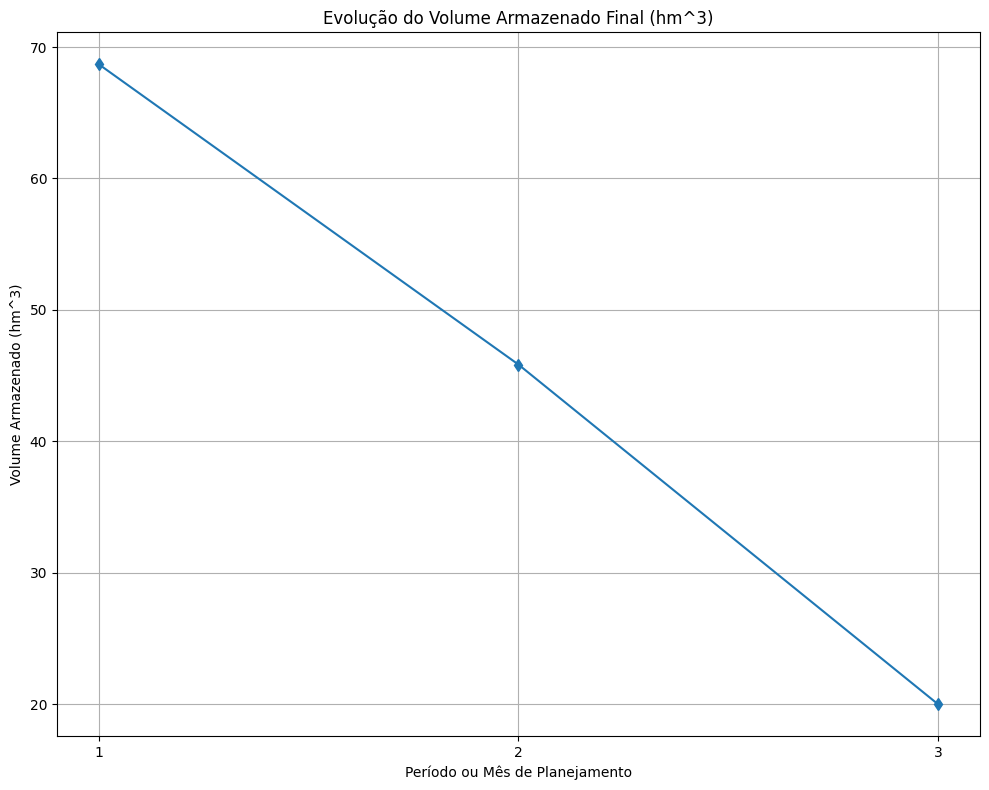

In [118]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0,sistema['DGer']['Nr_Est'],1)
plt.figure(figsize=(10,8))

for i, iusi in enumerate(resultado["UHE"]):
    plt.plot(x+1, iusi['vf'], marker='d')
plt.title('Evolução do Volume Armazenado Final (hm^3)')
plt.xlabel('Período ou Mês de Planejamento')
plt.ylabel('Volume Armazenado (hm^3)')
plt.xticks(x+1)
plt.grid()
plt.tight_layout()
plt.show()


## Plota Gráfico da Geração das UTEs

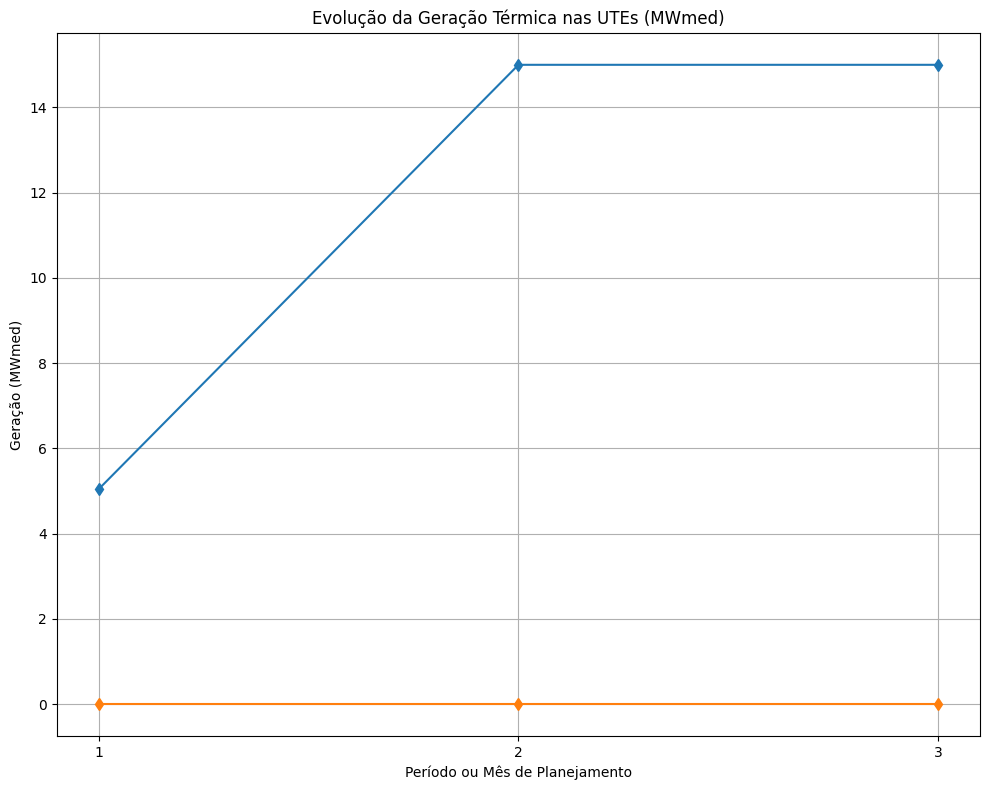

In [119]:
x = np.arange(0,sistema['DGer']['Nr_Est'],1)
plt.figure(figsize=(10,8))

for i, iusi in enumerate(resultado["UTE"]):
    plt.plot(x+1, iusi['gt'], marker='d')
plt.title('Evolução da Geração Térmica nas UTEs (MWmed)')
plt.xlabel('Período ou Mês de Planejamento')
plt.ylabel('Geração (MWmed)')
plt.xticks(x+1)
plt.grid()
plt.tight_layout()
plt.show()


#5 - PL Único 2 UHEs Código Adptado

## PL Único — Batalha e Serra do Facão em Cascata

**Disciplina:** Planejamento de Sistemas Elétricos — PPEE / UFJF

Adaptação didática do PL Único do professor, com **12 meses de afluências armazenadas** e **3 meses de simulação e gráficos (janeiro a março)**, duas UHEs em cascata e duas UTEs. Cada cenário de afluência é resolvido **separadamente**, com toda a sua trajetória mensal conhecida (despacho determinístico).

**Origem dos dados:** seção **3 — PDE Didática 2 UHEs Código Adaptado** do Colab oficial, consultada somente para leitura. O PL Único permanece independente da PDE.

**Premissa essencial:** para Serra do Facão, a afluência incremental foi obtida pela mesma **aproximação didática** do tópico 3: `max(0, vazão natural de Serra − vazão natural de Batalha)`, calculada separadamente para cada cenário. **Não é uma série histórica incremental validada**, pois os cenários média ± desvio-padrão não foram obtidos por pareamento de vazões anuais. A jusante, soma-se ainda o que Batalha turbina e verte, sem tempo de propagação.

**Convenções de unidades:** potência em MW médios; vazões naturais em m³/s; volumes e decisões hidráulicas do PL em hm³ por estágio. Cada estágio corresponde a 720 horas (30 dias). Custos térmicos e de déficit em R$/MWh são convertidos em reais por estágio.


## Dados de entrada — 12 meses, 2 UHEs em cascata e 2 UTEs

**Cenários no PL Único:** `0` = otimista; `1` = pessimista. O tópico 3 da PDE usa a ordem oposta (`0` = pessimista, `1` = otimista), então o código de dados reorganiza as colunas explicitamente.

As 12 afluências naturais de Batalha e de Serra do Facão foram **copiadas do tópico 3**, junto com o cálculo da afluência incremental didática de Serra. Os valores são convertidos para hm³ por estágio com `k = 720 × 3600 / 10⁶ = 2,592`.

A configuração didática padrão executa **3 meses (janeiro a março)** com carga de **150 MW médios**, mas mantém todas as **12 afluências de janeiro a dezembro** declaradas e disponíveis para futuramente ampliar o horizonte no Streamlit. **Os resultados dos dois modelos só são diretamente comparáveis depois de igualar também o horizonte e as hipóteses.**

Volumes iniciais: Batalha **430,05 hm³** (0% do volume útil); Serra do Facão **1.752,00 hm³** (0% do volume útil). A produtividade hidráulica e o engolimento são convertidos para as unidades do PL. A discretização da PDE não participa do PL Único.


In [120]:
# ============================================================
# PL ÚNICO — DADOS INDEPENDENTES DA PDE DIDÁTICA DE 2 UHEs
# Referência: tópico 3 do notebook Planejamento Energético Códigos Oficial.
# Só os DADOS foram transferidos, não o algoritmo estocástico da PDE.
# Afluências: média - 1 desvio / média + 1 desvio, m³/s.
# Incrementais de Serra = máximo(0, natural Serra - natural Batalha).
# ATENÇÃO: esta é uma hipótese DIDÁTICA e não uma série pareada validada.
# ============================================================

import numpy as np
import pandas as pd

horas = 720.0
k = horas * 3600.0 / 1_000_000.0  # 2,592 hm³ por m³/s em um estágio
meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
# Os 12 meses são preservados nos dados; o Colab calcula e exibe apenas 3.
meses_simulacao = meses[:3]

# Arrays originais da PDE: coluna 0 = pessimista, coluna 1 = otimista.
AFL_NAT_BATALHA_PL = np.array([
    [109.39, 261.01], [97.88, 277.97], [108.80, 270.99],
    [89.59, 198.60], [60.91, 122.33], [47.01, 91.64],
    [36.62, 72.28], [28.47, 57.15], [23.09, 50.30],
    [23.78, 62.43], [37.72, 112.72], [68.42, 209.66],
], dtype=float)
AFL_NAT_SERRA_PL = np.array([
    [179.45, 436.80], [161.44, 455.13], [174.79, 441.38],
    [144.15, 320.63], [96.82, 194.82], [74.60, 145.02],
    [58.21, 114.11], [45.44, 89.89], [37.40, 78.24],
    [39.01, 99.05], [63.67, 180.47], [111.85, 348.71],
], dtype=float)

# Mesma fórmula do tópico 3 (inclusive o corte em zero).
AFL_INC_SERRA_PL = np.maximum(0.0, AFL_NAT_SERRA_PL - AFL_NAT_BATALHA_PL)

# O PL Único original usa cenário 0 = otimista e cenário 1 = pessimista.
# A PDE usa a ordem inversa; reordenamos APENAS as colunas da afluência.
ordem_pl = [1, 0]

def afluencias_em_hm3(serie_m3s):
    return (serie_m3s[:, ordem_pl] * k).tolist()

lista_uhe = [
    {
        'Nome': 'UHE Batalha',
        'Vmin': 430.05,
        'Vmax': 1781.61,
        'VI': 430.05,
        'Prod': 0.3551 / k,     # PDE: 0,3551 MW/(m³/s)
        'Engol': 147.0 * k,     # PDE: 147,0 m³/s
        'Potencia': None,       # PDE não impõe um limite adicional de potência a Batalha
        'Jusante': 1,
        'Afl': afluencias_em_hm3(AFL_NAT_BATALHA_PL),
    },
    {
        'Nome': 'UHE Serra do Facão',
        'Vmin': 1752.0,
        'Vmax': 5199.0,
        'VI': 1752.0,
        'Prod': 0.6157 / k,     # PDE: 0,6157 MW/(m³/s)
        'Engol': 313.0 * k,     # PDE: 313,0 m³/s
        'Potencia': 212.58,    # Registrada na PDE; não limita o engolimento de 313 m³/s
        'Jusante': None,
        'Afl': afluencias_em_hm3(AFL_INC_SERRA_PL),
    },
]

lista_ute = [
    {'Nome': 'BBF Baliza', 'Capac': 18.0, 'Custo': 917.12 * horas},
    {'Nome': 'ERB Candeias', 'Capac': 17.0, 'Custo': 118.93 * horas},
]

d_gerais = {
    'Meses': meses_simulacao,
    'Horas': horas,
    'CDef': 8291.0 * horas,
    'Carga': [150.0] * len(meses_simulacao),
    'Nr_Disc': 5,              # Apenas referência didática; PL Único não usa discretização
    'Nr_Est': len(meses_simulacao),
    'Nr_Cen': 2,
}

sistema = {'DGer': d_gerais, 'UHE': lista_uhe, 'UTE': lista_ute}

# Verificações dos parâmetros, afluências e conversão de unidades.
assert k == 2.592
assert len(meses) == 12  # Afuências anuais preservadas
assert len(meses_simulacao) == len(sistema['DGer']['Carga']) == sistema['DGer']['Nr_Est'] == 3
assert all(len(u['Afl']) == 12 and all(len(par) == 2 for par in u['Afl']) for u in lista_uhe)
assert np.allclose(np.array(lista_uhe[0]['Afl']) / k, AFL_NAT_BATALHA_PL[:, ordem_pl])
assert np.allclose(np.array(lista_uhe[1]['Afl']) / k, AFL_INC_SERRA_PL[:, ordem_pl])

print(f'PL Único independente | Simulação: {len(meses_simulacao)} meses | Dados disponíveis: {len(meses)} meses | Carga: 150 MW médios')
print(f'Conversão: {k:.3f} hm³ por (m³/s) em {horas:.0f} horas')
print('Cenário 0 = otimista; cenário 1 = pessimista.')
print('AVISO: a afluência incremental de Serra é aproximação didática, não validada historicamente.')
for u in lista_uhe:
    print(f"{u['Nome']}: VI={u['VI']:.2f} hm³; Vmin={u['Vmin']:.2f}; "
          f"Vmax={u['Vmax']:.2f}; Vútil={u['Vmax']-u['Vmin']:.2f} hm³; "
          f"Prod={u['Prod']:.6f} MW/hm³; Engol={u['Engol']:.3f} hm³/mês")

print('\nAfluências transferidas da PDE: 12 meses disponíveis (m³/s):')
display(pd.DataFrame({
    'Mês': meses,
    'Batalha pess.': AFL_NAT_BATALHA_PL[:, 0],
    'Batalha otim.': AFL_NAT_BATALHA_PL[:, 1],
    'Serra inc. pess.': AFL_INC_SERRA_PL[:, 0],
    'Serra inc. otim.': AFL_INC_SERRA_PL[:, 1],
}).round(2))


PL Único independente | Simulação: 3 meses | Dados disponíveis: 12 meses | Carga: 150 MW médios
Conversão: 2.592 hm³ por (m³/s) em 720 horas
Cenário 0 = otimista; cenário 1 = pessimista.
AVISO: a afluência incremental de Serra é aproximação didática, não validada historicamente.
UHE Batalha: VI=430.05 hm³; Vmin=430.05; Vmax=1781.61; Vútil=1351.56 hm³; Prod=0.136998 MW/hm³; Engol=381.024 hm³/mês
UHE Serra do Facão: VI=1752.00 hm³; Vmin=1752.00; Vmax=5199.00; Vútil=3447.00 hm³; Prod=0.237539 MW/hm³; Engol=811.296 hm³/mês

Afluências transferidas da PDE: 12 meses disponíveis (m³/s):


,Mês,Batalha pess.,Batalha otim.,Serra inc. pess.,Serra inc. otim.
0,Jan,109.39,261.01,70.06,175.79
1,Fev,97.88,277.97,63.56,177.16
2,Mar,108.80,270.99,65.99,170.39
3,Abr,89.59,198.60,54.56,122.03
4,Mai,60.91,122.33,35.91,72.49
5,Jun,47.01,91.64,27.59,53.38
6,Jul,36.62,72.28,21.59,41.83
7,Ago,28.47,57.15,16.97,32.74
8,Set,23.09,50.30,14.31,27.94
9,Out,23.78,62.43,15.23,36.62


## Modelo matemático — PL Único com cascata

## 1. Balanço hídrico da Batalha (montante)

$$VF_{B,t} = VI_{B,t} + AFL_{B,t} - VT_{B,t} - VV_{B,t}$$

## 2. Balanço hídrico da Serra do Facão (jusante)

$$VF_{S,t} = VI_{S,t} + AFL_{S,t}^{\mathrm{inc}} + VT_{B,t} + VV_{B,t} - VT_{S,t} - VV_{S,t}$$

**Atenção:** a afluência incremental de Serra é adicional à água liberada pela Batalha. Todas as vazões acima são convertidas para **hm³ por estágio** nas restrições do PL.

## 3. Atendimento à demanda

$$Prod_B\,VT_{B,t}+Prod_S\,VT_{S,t}+GT_{Baliza,t}+GT_{Candeias,t}+DEF_t=150$$

## 4. Função objetivo do PL Único

$$\min\sum_{t=1}^{12}\left(720\cdot917{,}12\,GT_{Baliza,t}+720\cdot118{,}93\,GT_{Candeias,t}+720\cdot8291\,DEF_t+0{,}01\sum_i VV_{i,t}\right)$$

A demanda padrão é 150 MW médios por estágio (configurável na lista `d_gerais['Carga']`). Respeitam-se os limites de volume final, turbinamento e capacidades das UTEs. A água de Batalha chega a Serra no **mesmo mês** (hipótese didática).

**PL determinístico:** cada cenário completo de 12 meses é resolvido de uma vez, sem recursão da PDE ou cálculo de FCF.


In [121]:
try:
    from cvxopt.modeling import variable, solvers, op
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'cvxopt'])
    from cvxopt.modeling import variable, solvers, op


def pl_unico(sistema, cenario=1, imprime=False):
    """PL determinístico para UHEs em cascata, seguindo a estrutura da aula.

    cenario=0: afluências otimistas; cenario=1: pessimistas.
    Afluências das UHEs a jusante devem ser LOCAIS/INCREMENTAIS.
    """
    n = sistema['DGer']['Nr_Est']
    uhes, utes = sistema['UHE'], sistema['UTE']
    if not (isinstance(cenario, int) and 0 <= cenario < sistema['DGer']['Nr_Cen']):
        raise ValueError('Use cenario=0 (otimista) ou cenario=1 (pessimista).')
    if len(sistema['DGer']['Carga']) != n:
        raise ValueError('A carga precisa ter um valor para cada estágio.')

    # Variáveis de decisão: [usina][estágio].
    vf = [variable(n, 'VF ' + u['Nome']) for u in uhes]
    vt = [variable(n, 'VT ' + u['Nome']) for u in uhes]
    vv = [variable(n, 'VV ' + u['Nome']) for u in uhes]
    gt = [variable(n, 'GT ' + u['Nome']) for u in utes]
    deficit = variable(n, 'DEF')

    # Função objetivo: coeficientes Custo e CDef já estão em R$ por MWmédio/mês.
    fob = 0
    for t in range(n):
        for j, u in enumerate(utes):
            fob += u['Custo'] * gt[j][t]
        fob += sistema['DGer']['CDef'] * deficit[t]
        for i in range(len(uhes)):
            fob += 0.01 * vv[i][t]  # pequena penalidade pelo vertimento, R$/hm³

    restricoes = []
    balancos = [[None for t in range(n)] for u in uhes]
    atendimento = []

    # Balanço hídrico, incluindo água que chega das UHEs a montante.
    # UHE de montante aponta o índice da jusante via 'Jusante'.
    for i, u in enumerate(uhes):
        for t in range(n):
            vi = float(u['VI']) if t == 0 else vf[i][t - 1]
            afl_local = float(u['Afl'][t][cenario])
            recebimento = 0
            for j, montante in enumerate(uhes):
                if montante.get('Jusante') == i:
                    recebimento += vt[j][t] + vv[j][t]
            restricao = (vf[i][t] == vi + afl_local + recebimento - vt[i][t] - vv[i][t])
            restricoes.append(restricao)
            balancos[i][t] = restricao

    # Balanço de geração: MW hidrelétricos + MW termelétricos + déficit = carga.
    for t in range(n):
        geracao = 0
        for i, u in enumerate(uhes):
            geracao += u['Prod'] * vt[i][t]
        for j in range(len(utes)):
            geracao += gt[j][t]
        geracao += deficit[t]
        restricao = (geracao == float(sistema['DGer']['Carga'][t]))
        restricoes.append(restricao)
        atendimento.append(restricao)

    # Limites físicos das UHEs, limites das UTEs e déficit não negativo.
    for t in range(n):
        for i, u in enumerate(uhes):
            restricoes += [vf[i][t] >= u['Vmin'], vf[i][t] <= u['Vmax'],
                           vt[i][t] >= 0, vt[i][t] <= u['Engol'], vv[i][t] >= 0]
            if u.get('Potencia') is not None:
                restricoes.append(u['Prod'] * vt[i][t] <= u['Potencia'])
        for j, u in enumerate(utes):
            restricoes += [gt[j][t] >= 0, gt[j][t] <= u['Capac']]
        restricoes.append(deficit[t] >= 0)

    problema = op(fob, restricoes)
    solvers.options['show_progress'] = False
    problema.solve('dense', 'glpk')
    if problema.status != 'optimal':
        raise RuntimeError(f'O PL não encontrou solução ótima: {problema.status}')

    # CMA: multiplicador do balanço hídrico; CMO: -multiplicador de AD == Carga.
    # Com GLPK pode haver pequenas diferenças numéricas nos duais (solução degenerada).
    dados_uhe = []
    for i, u in enumerate(uhes):
        dados_uhe.append({
            'Nome': u['Nome'],
            'vf': [float(vf[i][t].value()[0]) for t in range(n)],
            'vt': [float(vt[i][t].value()[0]) for t in range(n)],
            'vv': [float(vv[i][t].value()[0]) for t in range(n)],
            'cma': [float(balancos[i][t].multiplier.value[0]) for t in range(n)],
        })
    dados_ute = []
    for j, u in enumerate(utes):
        dados_ute.append({'Nome': u['Nome'],
                          'gt': [float(gt[j][t].value()[0]) for t in range(n)]})
    dados_def = [float(deficit[t].value()[0]) for t in range(n)]
    cmo = [-float(atendimento[t].multiplier.value[0]) / sistema['DGer']['Horas']
           for t in range(n)]  # R$/MWh (corrige sinal da igualdade)
    custo_imediato = [sum(utes[j]['Custo'] * dados_ute[j]['gt'][t]
                           for j in range(len(utes)))
                      + sistema['DGer']['CDef'] * dados_def[t]
                      + 0.01 * sum(dados_uhe[i]['vv'][t] for i in range(len(uhes)))
                      for t in range(n)]
    resultado = {
        'DGer': {'CustoTotal': float(fob.value()[0]), 'CMO': cmo,
                 'Deficit': dados_def, 'CustoImediato': custo_imediato,
                 'Cenario': cenario},
        'UHE': dados_uhe,
        'UTE': dados_ute,
    }
    if imprime:
        print('Custo total: R$', f"{resultado['DGer']['CustoTotal']:,.2f}")
        print('CMO (R$/MWh):', np.round(cmo, 2))
        print('Déficit (MW):', np.round(dados_def, 3))
    return resultado


## Programa principal — simular os dois cenários

O **PL Único determinístico** otimiza separadamente as trajetórias otimista e pessimista de **3 meses (janeiro a março)**, usando as afluências do tópico 3, com carga padrão de 150 MW médios.

Os resultados **não são uma média probabilística**. A função `pl_unico` permanece a mesma, com a conexão **Batalha → Serra do Facão**.


In [122]:
# Instale a biblioteca no Colab caso ainda não esteja disponível:
# %pip -q install cvxopt

resultado_otimista = pl_unico(sistema, 0, imprime=True)
resultado_pessimista = pl_unico(sistema, 1, imprime=True)

# Para os gráficos originais, escolha qual trajetória mostrar:
resultado = resultado_pessimista


def tabela_resultados(sistema, resultado):
    linhas = []
    n = sistema['DGer']['Nr_Est']
    for t in range(n):
        linha = {'Mês': sistema['DGer']['Meses'][t],
                 'Carga (MW)': sistema['DGer']['Carga'][t]}
        for i, u in enumerate(sistema['UHE']):
            linha[f'VI {u["Nome"]} (hm³)'] = u['VI'] if t == 0 else resultado['UHE'][i]['vf'][t-1]
            linha[f'AFL local {u["Nome"]} (hm³)'] = u['Afl'][t][resultado['DGer']['Cenario']]
            linha[f'VT {u["Nome"]} (hm³)'] = resultado['UHE'][i]['vt'][t]
            linha[f'VV {u["Nome"]} (hm³)'] = resultado['UHE'][i]['vv'][t]
            linha[f'VF {u["Nome"]} (hm³)'] = resultado['UHE'][i]['vf'][t]
            linha[f'Geração {u["Nome"]} (MW)'] = u['Prod'] * resultado['UHE'][i]['vt'][t]
        for j, u in enumerate(sistema['UTE']):
            linha[f'{u["Nome"]} (MW)'] = resultado['UTE'][j]['gt'][t]
        linha['Déficit (MW)'] = resultado['DGer']['Deficit'][t]
        linha['CMO (R$/MWh)'] = resultado['DGer']['CMO'][t]
        linha['Custo imediato (R$)'] = resultado['DGer']['CustoImediato'][t]
        linhas.append(linha)
    return pd.DataFrame(linhas)

print('\n=== CENÁRIO OTIMISTA (afluências maiores) ===')
display(tabela_resultados(sistema, resultado_otimista).round(3))
print('\n=== CENÁRIO PESSIMISTA (afluências menores) ===')
display(tabela_resultados(sistema, resultado_pessimista).round(3))

print('\n=== CUSTO TOTAL DOS 3 MESES SIMULADOS ===')
for nome, res in [('Otimista', resultado_otimista), ('Pessimista', resultado_pessimista)]:
    print(f"{nome}: R$ {res['DGer']['CustoTotal']:,.2f}")


Custo total: R$ 0.00
CMO (R$/MWh): [0. 0. 0.]
Déficit (MW): [0. 0. 0.]
Custo total: R$ 1,734,801.49
CMO (R$/MWh): [118.93 118.93 118.93]
Déficit (MW): [ 0.  0. -0.]

=== CENÁRIO OTIMISTA (afluências maiores) ===


,Mês,Carga (MW),VI UHE Batalha (hm³),AFL local UHE Batalha (hm³),VT UHE Batalha (hm³),VV UHE Batalha (hm³),VF UHE Batalha (hm³),Geração UHE Batalha (MW),VI UHE Serra do Facão (hm³),AFL local UHE Serra do Facão (hm³),VT UHE Serra do Facão (hm³),VV UHE Serra do Facão (hm³),VF UHE Serra do Facão (hm³),Geração UHE Serra do Facão (MW),BBF Baliza (MW),ERB Candeias (MW),Déficit (MW),CMO (R$/MWh),Custo imediato (R$)
0,Jan,150.0,430.050,676.538,366.858,0.0,739.730,50.259,1752.000,455.648,419.894,0.0,2154.612,99.741,0.0,0.0,0.0,0.0,0.0
1,Fev,150.0,739.730,720.498,0.000,-0.0,1460.228,0.000,2154.612,459.199,631.476,-0.0,1982.334,150.000,-0.0,0.0,0.0,0.0,0.0
2,Mar,150.0,1460.228,702.406,381.024,0.0,1781.610,52.200,1982.334,441.651,411.724,0.0,2393.285,97.800,0.0,0.0,0.0,0.0,0.0



=== CENÁRIO PESSIMISTA (afluências menores) ===


,Mês,Carga (MW),VI UHE Batalha (hm³),AFL local UHE Batalha (hm³),VT UHE Batalha (hm³),VV UHE Batalha (hm³),VF UHE Batalha (hm³),Geração UHE Batalha (MW),VI UHE Serra do Facão (hm³),AFL local UHE Serra do Facão (hm³),VT UHE Serra do Facão (hm³),VV UHE Serra do Facão (hm³),VF UHE Serra do Facão (hm³),Geração UHE Serra do Facão (MW),BBF Baliza (MW),ERB Candeias (MW),Déficit (MW),CMO (R$/MWh),Custo imediato (R$)
0,Jan,150.0,430.050,283.539,241.235,-0.0,472.353,33.049,1752.0,181.596,422.831,0.0,1752.0,100.439,0.0,16.512,0.0,118.93,1413954.489
1,Fev,150.0,472.353,253.705,296.008,0.0,430.050,40.553,1752.0,164.748,460.756,0.0,1752.0,109.447,0.0,-0.000,0.0,118.93,-0.000
2,Mar,150.0,430.050,282.010,282.010,0.0,430.050,38.635,1752.0,171.046,453.056,0.0,1752.0,107.618,0.0,3.747,-0.0,118.93,320847.004



=== CUSTO TOTAL DOS 3 MESES SIMULADOS ===
Otimista: R$ 0.00
Pessimista: R$ 1,734,801.49


## Gráfico — evolução do armazenamento

A comparação usa **% do volume útil** para as duas UHEs, já que os tamanhos dos reservatórios são muito diferentes. O resultado hidráulico da Serra **inclui** a defluência de Batalha.


In [123]:

# ============================================================
# GRÁFICO PYECHARTS — EVOLUÇÃO DO VOLUME ÚTIL DAS DUAS UHEs
# Quatro trajetórias: duas UHEs × dois cenários.
# Utiliza somente os despachos previamente calculados pelo PL Único.
# ============================================================

import numpy as np
from IPython.display import HTML, display
from pyecharts import options as opts
from pyecharts.charts import Line
from pyecharts.globals import ThemeType

categorias_volume = ['Inicial'] + list(sistema['DGer']['Meses'])

cores_volume = {
    ('UHE Batalha', 'Otimista'): '#2684C2',
    ('UHE Batalha', 'Pessimista'): '#D88647',
    ('UHE Serra do Facão', 'Otimista'): '#24A896',
    ('UHE Serra do Facão', 'Pessimista'): '#BC5B70',
}

linha_volume = Line(
    init_opts=opts.InitOpts(
        width='1100px',
        height='510px',
        theme=ThemeType.LIGHT
    )
)

linha_volume.add_xaxis(categorias_volume)

for nome_cenario, res, tracejado in [
    ('Otimista', resultado_otimista, False),
    ('Pessimista', resultado_pessimista, True),
]:
    for i, u in enumerate(sistema['UHE']):

        volumes = (
            [float(u['VI'])]
            + [float(v) for v in res['UHE'][i]['vf']]
        )

        percentuais = [
            100.0 * (v - u['Vmin']) / (u['Vmax'] - u['Vmin'])
            for v in volumes
        ]

        cor = cores_volume.get(
            (u['Nome'], nome_cenario),
            '#555555'
        )

        linha_volume.add_yaxis(
            series_name=f"{u['Nome']} — {nome_cenario}",
            y_axis=percentuais,
            is_smooth=False,
            is_symbol_show=True,
            symbol_size=9,
            linestyle_opts=opts.LineStyleOpts(
                width=3,
                type_='dashed' if tracejado else 'solid',
                color=cor
            ),
            itemstyle_opts=opts.ItemStyleOpts(color=cor),
            label_opts=opts.LabelOpts(is_show=False),
        )

linha_volume.set_global_opts(
    title_opts=opts.TitleOpts(
        title='Evolução do volume útil armazenado',
        subtitle=(
            'PL Único — Batalha e Serra do Facão '
            '| otimista × pessimista'
        )
    ),
    tooltip_opts=opts.TooltipOpts(trigger='axis'),
    legend_opts=opts.LegendOpts(
        pos_top='13%',
        type_='scroll'
    ),
    xaxis_opts=opts.AxisOpts(
        name='Estágio',
        name_location='middle',
        name_gap=28
    ),
    yaxis_opts=opts.AxisOpts(
        name='Volume útil (%)',
        min_=0,
        max_=100,
        axislabel_opts=opts.LabelOpts(
            formatter='{value}%'
        )
    ),
    datazoom_opts=[
        opts.DataZoomOpts(type_='inside')
    ],
    toolbox_opts=opts.ToolboxOpts(
        is_show=True,
        feature={'saveAsImage': {}}
    ),
)

# Corrige a configuração do grid sem usar
# grid_opts dentro de set_global_opts().
linha_volume.options['grid'] = {
    'top': '26%',
    'bottom': '15%',
    'left': '9%',
    'right': '5%'
}

display(HTML(linha_volume.render_embed()))


## Gráficos — geração por fonte e custos

Os gráficos mostram a geração hidráulica, as duas térmicas e o eventual déficit de cada cenário. O custo é o **custo imediato em cada mês**, somado na FOB total do PL Único.


In [124]:

# ============================================================
# GRÁFICOS PYECHARTS — COMPOSIÇÃO DA GERAÇÃO E CUSTO IMEDIATO
# Reutiliza resultados calculados, sem executar novos despachos.
# ============================================================

import numpy as np
from IPython.display import HTML, display
from pyecharts import options as opts
from pyecharts.charts import Bar, Line
from pyecharts.globals import ThemeType

meses_graficos = list(sistema['DGer']['Meses'])

fontes = (
    [u['Nome'] for u in sistema['UHE']]
    + [u['Nome'] for u in sistema['UTE']]
    + ['Déficit']
)

cores_fontes = [
    '#327AB5',
    '#2A9D8F',
    '#D79959',
    '#A66B51',
    '#B64960'
]

# ============================================================
# 1 — COMPOSIÇÃO DA GERAÇÃO MENSAL
# ============================================================

for nome_cenario, res in [
    ('Pessimista', resultado_pessimista),
    ('Otimista', resultado_otimista)
]:

    valores = np.array([
        (
            [
                float(u['Prod']) * float(res['UHE'][i]['vt'][t])
                for i, u in enumerate(sistema['UHE'])
            ]
            + [
                float(res['UTE'][j]['gt'][t])
                for j in range(len(sistema['UTE']))
            ]
            + [
                float(res['DGer']['Deficit'][t])
            ]
        )
        for t in range(len(meses_graficos))
    ])

    barras = Bar(
        init_opts=opts.InitOpts(
            width='1100px',
            height='480px',
            theme=ThemeType.LIGHT
        )
    )

    barras.add_xaxis(meses_graficos)

    for j, fonte in enumerate(fontes):
        barras.add_yaxis(
            series_name=fonte,
            y_axis=valores[:, j].tolist(),
            stack='atendimento',
            category_gap='42%',
            itemstyle_opts=opts.ItemStyleOpts(
                color=cores_fontes[j]
            ),
            label_opts=opts.LabelOpts(is_show=False),
        )

    barras.set_global_opts(
        title_opts=opts.TitleOpts(
            title=(
                f'Composição da geração mensal — '
                f'cenário {nome_cenario.lower()}'
            ),
            subtitle='UHEs, UTEs e déficit | MW médios'
        ),
        tooltip_opts=opts.TooltipOpts(
            trigger='axis',
            axis_pointer_type='shadow'
        ),
        legend_opts=opts.LegendOpts(
            type_='scroll',
            pos_top='14%'
        ),
        xaxis_opts=opts.AxisOpts(
            name='Mês',
            name_location='middle',
            name_gap=25
        ),
        yaxis_opts=opts.AxisOpts(
            name='Geração e déficit (MW médios)',
            min_=0
        ),
        toolbox_opts=opts.ToolboxOpts(
            is_show=True,
            feature={'saveAsImage': {}}
        ),
    )

    # Linha de referência da carga mensal
    demanda = Line()
    demanda.add_xaxis(meses_graficos)

    demanda.add_yaxis(
        series_name='Carga (MW médios)',
        y_axis=[
            float(x)
            for x in sistema['DGer']['Carga']
        ],
        symbol_size=8,
        linestyle_opts=opts.LineStyleOpts(
            color='#263238',
            type_='dashed',
            width=2
        ),
        itemstyle_opts=opts.ItemStyleOpts(
            color='#263238'
        ),
        label_opts=opts.LabelOpts(is_show=False),
    )

    barras.overlap(demanda)

    # Correção: o grid deve ser configurado fora
    # do método set_global_opts().
    barras.options['grid'] = {
        'top': '28%',
        'bottom': '16%',
        'left': '10%',
        'right': '5%'
    }

    display(HTML(barras.render_embed()))


# ============================================================
# 2 — CUSTO IMEDIATO MENSAL POR CENÁRIO
# ============================================================

# Custos originais em reais
custos_p = np.array(
    resultado_pessimista['DGer']['CustoImediato'],
    dtype=float
)

custos_o = np.array(
    resultado_otimista['DGer']['CustoImediato'],
    dtype=float
)

# Conversão apenas para a apresentação
maior_custo = max(
    float(np.max(np.abs(custos_p))),
    float(np.max(np.abs(custos_o)))
)

usar_milhoes = maior_custo >= 1_000_000
divisor = 1_000_000 if usar_milhoes else 1.0
unidade = 'milhões de R$' if usar_milhoes else 'R$'

barras_custo = Bar(
    init_opts=opts.InitOpts(
        width='1100px',
        height='470px',
        theme=ThemeType.LIGHT
    )
)

barras_custo.add_xaxis(meses_graficos)

barras_custo.add_yaxis(
    series_name='Pessimista',
    y_axis=(custos_p / divisor).tolist(),
    itemstyle_opts=opts.ItemStyleOpts(
        color='#D88647'
    ),
    label_opts=opts.LabelOpts(is_show=False),
)

barras_custo.add_yaxis(
    series_name='Otimista',
    y_axis=(custos_o / divisor).tolist(),
    itemstyle_opts=opts.ItemStyleOpts(
        color='#2684C2'
    ),
    label_opts=opts.LabelOpts(is_show=False),
)

barras_custo.set_global_opts(
    title_opts=opts.TitleOpts(
        title='Custo imediato mensal por cenário',
        subtitle=(
            'Custos de geração térmica, déficit e '
            'vertimento — sem custo futuro'
        )
    ),
    tooltip_opts=opts.TooltipOpts(
        trigger='axis',
        axis_pointer_type='shadow'
    ),
    legend_opts=opts.LegendOpts(
        pos_top='13%'
    ),
    xaxis_opts=opts.AxisOpts(
        name='Mês',
        name_location='middle',
        name_gap=26
    ),
    yaxis_opts=opts.AxisOpts(
        name=f'Custo imediato ({unidade})',
        min_=0
    ),
    toolbox_opts=opts.ToolboxOpts(
        is_show=True,
        feature={'saveAsImage': {}}
    ),
)

# Correção do grid do gráfico de custos
barras_custo.options['grid'] = {
    'top': '26%',
    'bottom': '16%',
    'left': '13%',
    'right': '6%'
}

display(HTML(barras_custo.render_embed()))

print(
    f'Escala monetária do gráfico: {unidade}. '
    'Os custos calculados permanecem armazenados em R$.'
)


Escala monetária do gráfico: milhões de R$. Os custos calculados permanecem armazenados em R$.
